## <span style="color: red;">Import</span>

### <span style="color: green;">Import des packages</span>

In [1]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt

### <span style="color: green;">Import de la Dataset</span>

In [2]:
# Option 1 -- Adult / Census Income
adult = fetch_openml(name="adult", version=2, as_frame=True)
X, y = adult.data, adult.target

## <span style="color: red;">1 - Analyse exploratoire (EDA) et cadrage du problème</span> 

### <span style="color: green;">Analyse de la DataSet</span> 

#### Aperçu

In [3]:
df = adult.frame

In [4]:
df.shape

(48842, 15)

Le dataset contient 48 842 lignes, une par personne, et 15 colonnes : 14 variables descriptives et la cible `class`.

In [5]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='str')

In [6]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


Chaque ligne décrit une personne. On voit dès les premières lignes des valeurs manquantes (`NaN`) dans `workclass` et `occupation`.

In [7]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
48841,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [8]:
df.sample(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
24229,47,Private,214702,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,37,Puerto-Rico,<=50K
5202,21,Private,140001,Some-college,10,Never-married,Adm-clerical,Own-child,White,Male,0,0,10,United-States,<=50K
398,36,Private,116358,Masters,14,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,0,0,45,India,<=50K
45241,36,Private,204590,Bachelors,13,Divorced,Prof-specialty,Unmarried,Black,Female,0,213,40,United-States,<=50K
10936,39,Self-emp-inc,172927,Assoc-acdm,12,Married-civ-spouse,Prof-specialty,Husband,White,Male,15024,0,50,United-States,>50K


#### Doublons

In [9]:
df[df.duplicated(keep=False)].sort_values(list(df.columns))

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
4152,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
40948,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
3900,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
15960,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
33954,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38156,49,Private,31267,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
23334,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
38775,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
18584,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K


Ce tableau liste les 101 lignes qui existent en plusieurs exemplaires : 52 d'entre elles sont des copies en trop, soit 0,1 % du dataset.

Les lignes en double sont identiques jusqu'au poids `fnlwgt`, qui prend pourtant des dizaines de milliers de valeurs différentes : une coïncidence est peu probable.

In [10]:
# 52 lignes strictement identiques sur les 15 variables, y compris le poids d’échantillonnage. 
# En l’absence d’identifiant, nous les considérons comme des doublons de saisie et les supprimons, 
# pour éviter qu’une même observation figure à la fois dans le jeu d’entraînement et dans le jeu de test.

df = df.drop_duplicates().reset_index(drop=True)
df.shape

(48790, 15)

In [11]:
df.duplicated().sum()

np.int64(0)

#### Types et valeurs manquantes

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48790 entries, 0 to 48789
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48790 non-null  int64   
 1   workclass       45995 non-null  category
 2   fnlwgt          48790 non-null  int64   
 3   education       48790 non-null  category
 4   education-num   48790 non-null  int64   
 5   marital-status  48790 non-null  category
 6   occupation      45985 non-null  category
 7   relationship    48790 non-null  category
 8   race            48790 non-null  category
 9   sex             48790 non-null  category
 10  capital-gain    48790 non-null  int64   
 11  capital-loss    48790 non-null  int64   
 12  hours-per-week  48790 non-null  int64   
 13  native-country  47934 non-null  category
 14  class           48790 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


Les types sont corrects : 6 variables numériques (`int64`) et 9 catégorielles (`category`). Trois colonnes ont des valeurs manquantes : `workclass`, `occupation` et `native-country`.

In [13]:
df.nunique(dropna=False) == 1

age               False
workclass         False
fnlwgt            False
education         False
education-num     False
marital-status    False
occupation        False
relationship      False
race              False
sex               False
capital-gain      False
capital-loss      False
hours-per-week    False
native-country    False
class             False
dtype: bool

Aucune colonne n'est constante : toutes les variables peuvent apporter de l'information.

<Axes: >

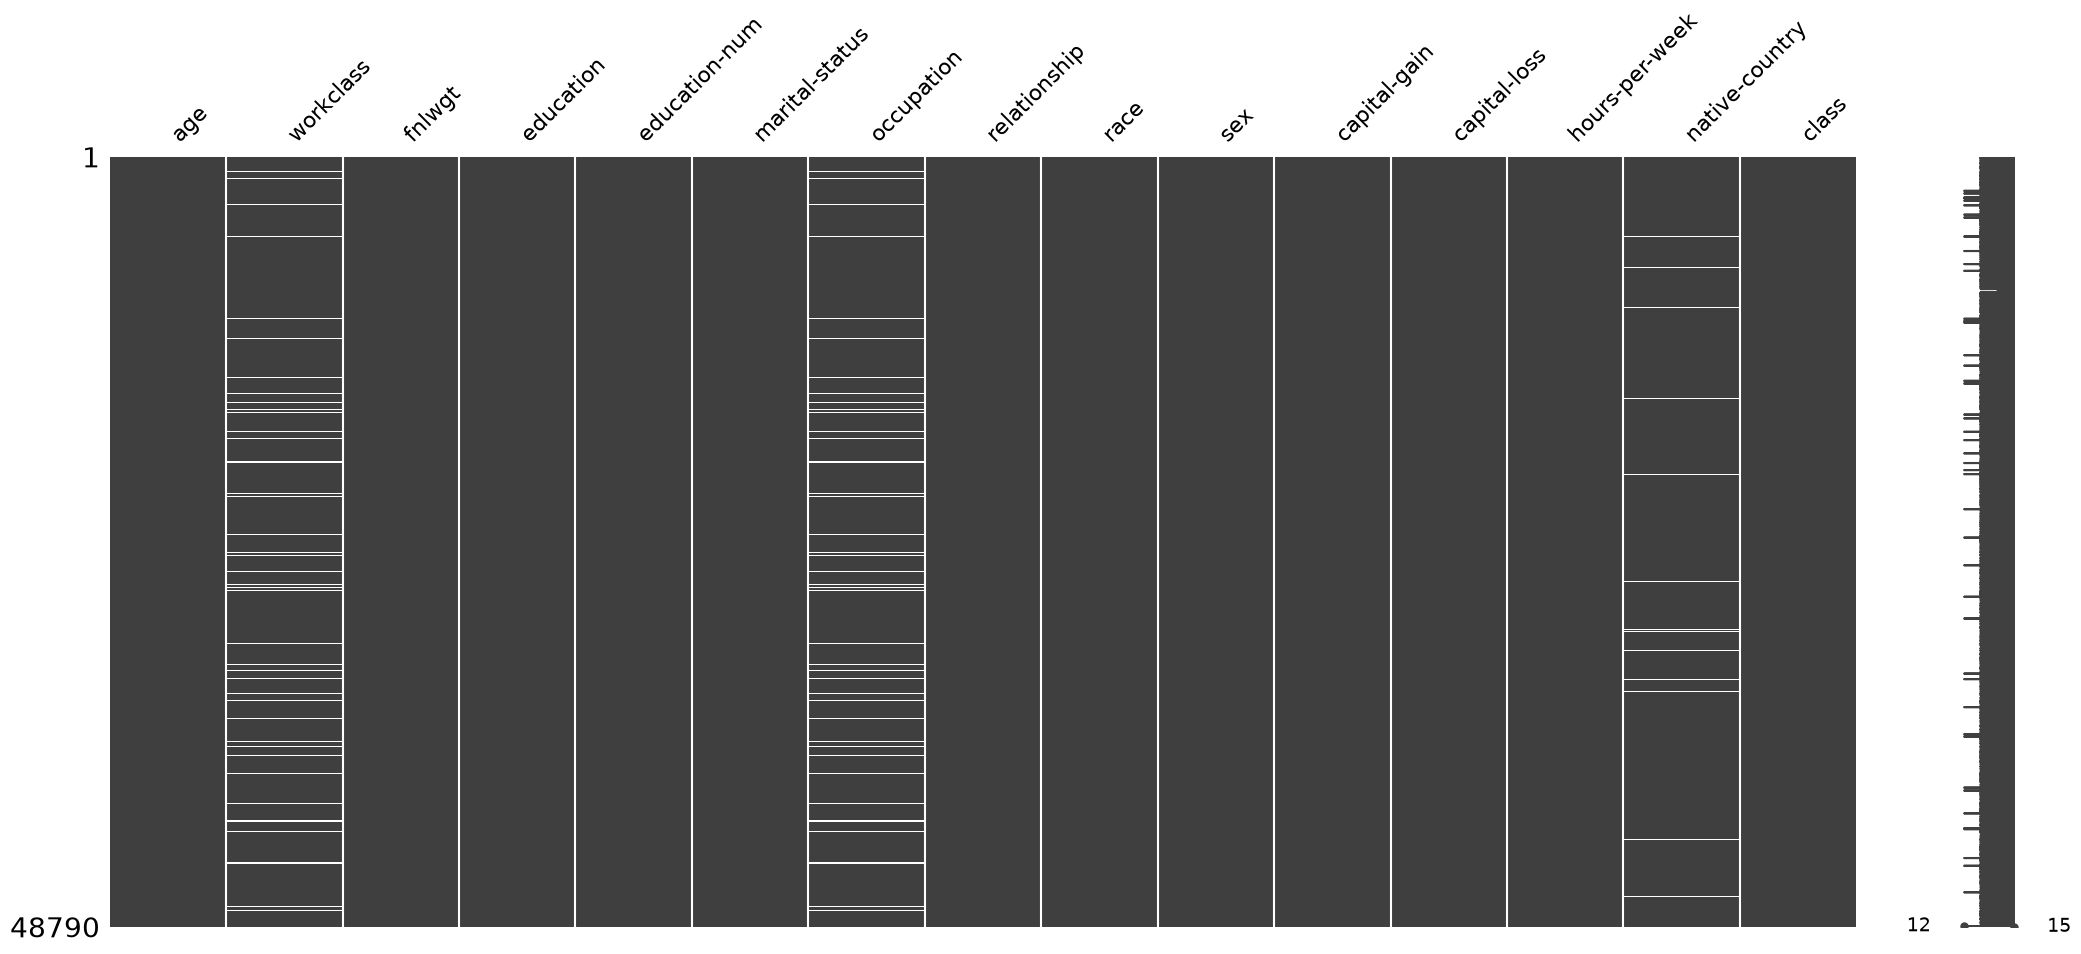

In [14]:
msno.matrix(df)

Les traits blancs sont les valeurs manquantes : elles ne concernent que `workclass`, `occupation` et `native-country`. Celles de `workclass` et `occupation` tombent sur les mêmes lignes.

In [15]:
df[["workclass", "occupation", "native-country"]].isna().value_counts()

workclass  occupation  native-country
False      False       False             45175
True       True        False              2749
False      False       True                810
True       True        True                 46
False      True        False                10
Name: count, dtype: int64

`workclass` et `occupation` manquent ensemble sur 2 795 lignes (2 749 + 46), alors que `native-country` manque le plus souvent seule (810 lignes). Dans 10 lignes seule `occupation` manque : ce sont les personnes `Never-worked`.

In [16]:
df.isna().mean()

age               0.000000
workclass         0.057286
fnlwgt            0.000000
education         0.000000
education-num     0.000000
marital-status    0.000000
occupation        0.057491
relationship      0.000000
race              0.000000
sex               0.000000
capital-gain      0.000000
capital-loss      0.000000
hours-per-week    0.000000
native-country    0.017545
class             0.000000
dtype: float64

Les taux restent faibles : 5,7 % pour `workclass` et `occupation`, 1,8 % pour `native-country`. Aucune colonne n'est à écarter à cause des valeurs manquantes.

#### Variables numériques

In [17]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48790.000000,4.879000e+04,48790.000000,48790.000000,48790.000000,48790.000000
mean,38.652798,1.896690e+05,10.078807,1080.217688,87.595573,40.425886
std,13.708493,1.056172e+05,2.570046,7455.905921,403.209129,12.392729
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781385e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376062e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


L'âge va de 17 à 90 ans (médiane 37) et le temps de travail médian est de 40 h par semaine. `capital-gain` et `capital-loss` valent 0 pour au moins 75 % des personnes, et le maximum de `capital-gain` (99 999) est très éloigné du reste.

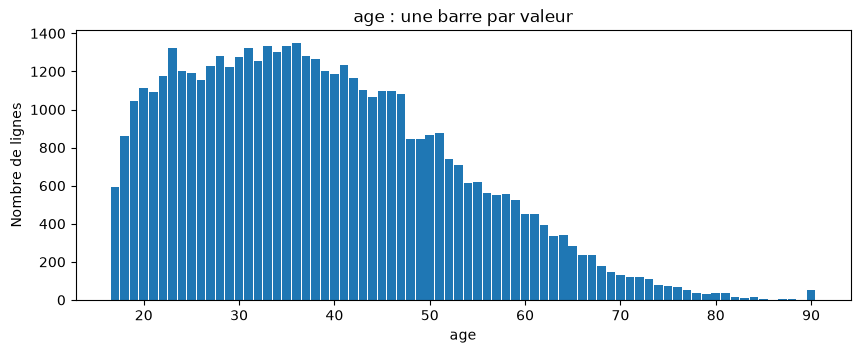

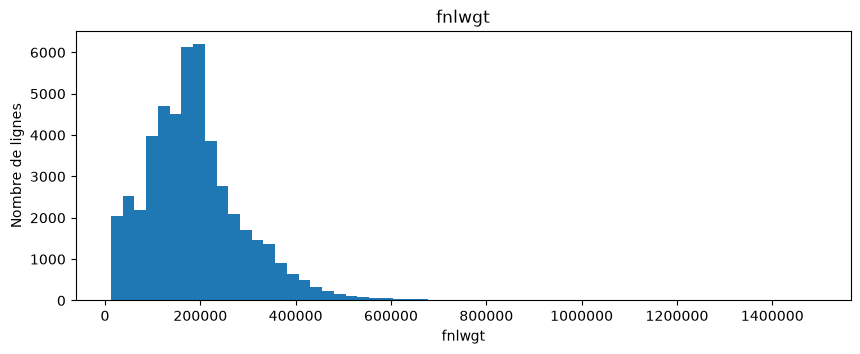

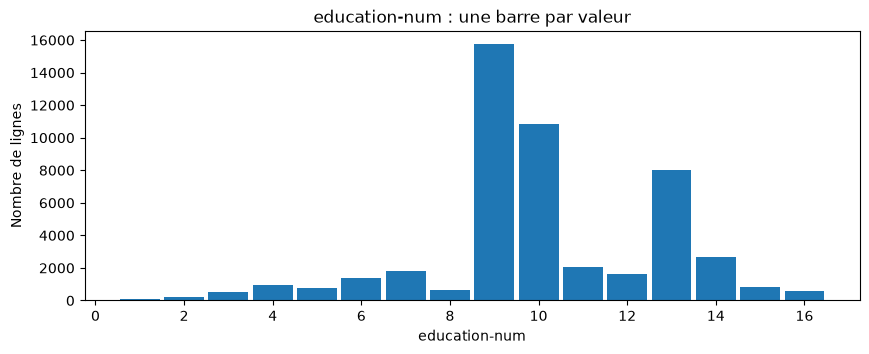

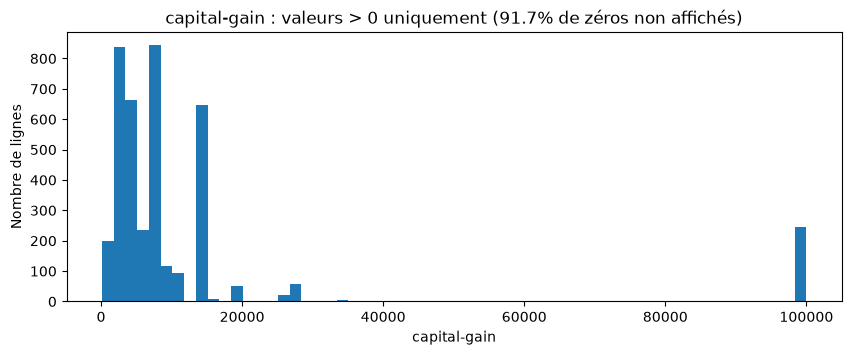

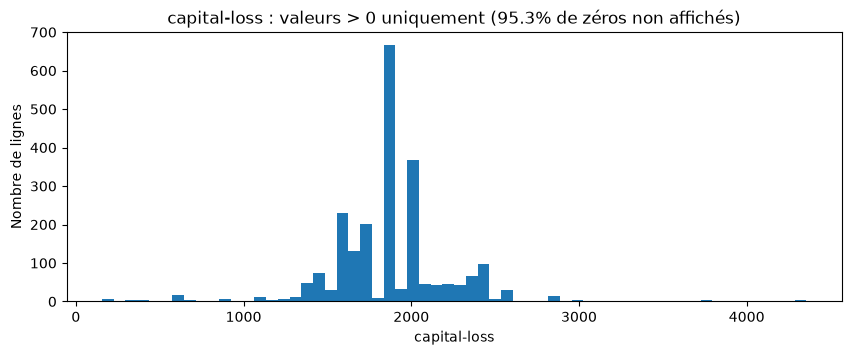

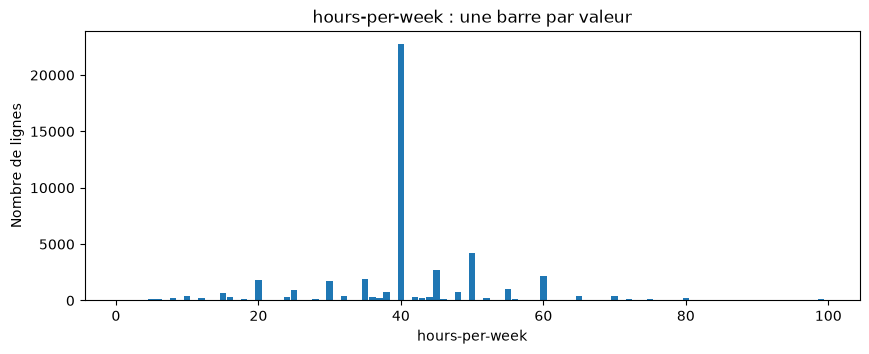

In [18]:
for col in df.select_dtypes("number"):
    s = df[col]
    part_zeros = (s == 0).mean()
    fig, ax = plt.subplots(figsize=(10, 3.5))

    if part_zeros > 0.5:
        # capital-gain, capital-loss : presque que des zéros, on trace le reste
        ax.hist(s[s > 0], bins=60)
        ax.set_title(f"{col} : valeurs > 0 uniquement ({part_zeros:.1%} de zéros non affichés)")
    elif s.nunique() <= 100:
        # age, education-num, hours-per-week : valeurs entières, une barre par valeur
        counts = s.value_counts().sort_index()
        ax.bar(counts.index, counts.values, width=0.9)
        ax.set_title(f"{col} : une barre par valeur")
    else:
        # fnlwgt : variable continue, histogramme classique
        ax.hist(s, bins=60)
        ax.ticklabel_format(style="plain", axis="x")
        ax.set_title(col)

    ax.set_xlabel(col)
    ax.set_ylabel("Nombre de lignes")
    plt.show()

`hours-per-week` a un pic très net à 40 h et `education-num` trois niveaux dominants (9, 10 et 13). Pour `capital-gain`, une barre isolée apparaît à 99 999, étudiée juste en dessous ; `age` montre aussi un petit regroupement à 90.

In [19]:
(df["capital-gain"] == 99999).sum()

np.int64(244)

Le 99 999 de capital-gain est un plafond de saisie

In [20]:
tranches = pd.cut(df["capital-gain"], [-1, 0, 5000, 10000, 41310, 99999])
(df["class"] == ">50K").groupby(tranches, observed=True).agg(["size", "mean"])

,size,mean
capital-gain,,
"(-1, 0]",44755,0.205340
"(0, 5000]",1584,0.178662
"(5000, 10000]",1317,0.829157
"(10000, 41310]",890,0.979775
"(41310, 99999]",244,1.000000


Le taux de `>50K` est d'environ 20 % sans gain en capital, puis monte à 83 % entre 5 000 et 10 000 et à 98 % au-delà. Les 244 personnes au plafond sont toutes en `>50K` : ces lignes sont informatives, on les garde.

#### Variables catégorielles

In [21]:
df.describe(include="category")

,workclass,education,marital-status,occupation,relationship,race,sex,native-country,class
count,45995,48790,48790,45985,48790,48790,48790,47934,48790
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,33860,15770,22366,6165,19703,41714,32614,43792,37109


`native-country` a le plus de modalités (41), mais `United-States` représente 91 % des valeurs renseignées. La cible est déséquilibrée : 76 % des personnes sont en `<=50K`.

In [22]:
for col in df.select_dtypes("category"):
    display(df[col].value_counts(dropna=False))

workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
NaN                  2795
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
9th               756
12th              655
Doctorate         594
5th-6th           507
1st-4th           245
Preschool          81
Name: count, dtype: int64

marital-status
Married-civ-spouse       22366
Never-married            16082
Divorced                  6630
Separated                 1530
Widowed                   1518
Married-spouse-absent      627
Married-AF-spouse           37
Name: count, dtype: int64

occupation
Prof-specialty       6165
Craft-repair         6102
Exec-managerial      6082
Adm-clerical         5606
Sales                5501
Other-service        4919
Machine-op-inspct    3017
NaN                  2805
Transport-moving     2355
Handlers-cleaners    2071
Farming-fishing      1485
Tech-support         1445
Protective-serv       982
Priv-house-serv       240
Armed-Forces           15
Name: count, dtype: int64

relationship
Husband           19703
Not-in-family     12557
Own-child          7569
Unmarried          5124
Wife               2331
Other-relative     1506
Name: count, dtype: int64

race
White                 41714
Black                  4683
Asian-Pac-Islander     1517
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64

sex
Male      32614
Female    16176
Name: count, dtype: int64

native-country
United-States                 43792
Mexico                          943
NaN                             856
Philippines                     294
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Poland                           87
Guatemala                        86
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                        49
Peru         

class
<=50K    37109
>50K     11681
Name: count, dtype: int64

Certaines modalités sont très rares : `Never-worked` (10), `Armed-Forces` (15), `Without-pay` (21), `Married-AF-spouse` (37). `native-country` est dominée par `United-States` (43 792 lignes), les 40 autres pays se partageant le reste.

#### Cohérence et redondances

In [23]:
df.groupby("education", observed=True)["education-num"].unique()

education
10th             [6]
11th             [7]
12th             [8]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
Assoc-acdm      [12]
Assoc-voc       [11]
Bachelors       [13]
Doctorate       [16]
HS-grad          [9]
Masters         [14]
Preschool        [1]
Prof-school     [15]
Some-college    [10]
Name: education-num, dtype: object

Chaque diplôme correspond à un seul numéro : `education` et `education-num` portent la même information. Une seule des deux suffira pour le modèle ; `education-num` a l'avantage de conserver l'ordre des niveaux d'études.

In [24]:
pd.crosstab(df["relationship"], df["sex"])

sex,Female,Male
relationship,,
Husband,1,19702
Not-in-family,5861,6696
Other-relative,689,817
Own-child,3370,4199
Unmarried,3927,1197
Wife,2328,3


Les deux variables sont cohérentes à 4 lignes près : 1 `Husband` de sexe féminin et 3 `Wife` de sexe masculin, probablement des erreurs de saisie. C'est négligeable sur 48 790 lignes.

In [25]:
pd.crosstab(df["relationship"], df["marital-status"])

marital-status,Divorced,Married-AF-spouse,Married-civ-spouse,Married-spouse-absent,Never-married,Separated,Widowed
relationship,,,,,,,
Husband,0,12,19691,0,0,0,0
Not-in-family,3626,0,23,329,7091,637,851
Other-relative,181,1,201,54,920,79,70
Own-child,455,1,143,61,6738,146,25
Unmarried,2368,0,0,183,1333,668,572
Wife,0,23,2308,0,0,0,0


Tous les `Husband` et `Wife` sont bien mariés (`Married-civ-spouse` ou `Married-AF-spouse`). `relationship` et `marital-status` se recoupent donc en partie, sans être redondantes.

#### Bilan de l'analyse de la dataset

Après suppression de 52 doublons, le dataset compte **48 790 lignes et 15 colonnes** : 6 numériques et 9 catégorielles, dont la cible `class`.

| Constat | Conséquence pour le preprocessing |
|---|---|
| 52 lignes en double | Supprimées. |
| Valeurs manquantes sur 3 colonnes : `workclass` et `occupation` (5,7 %, sur les mêmes lignes), `native-country` (1,8 %) | Traitement à choisir : imputation ou modalité « inconnu ». Aucune colonne à écarter. |
| `fnlwgt` est un poids de sondage, pas une caractéristique de la personne | À retirer des variables du modèle. |
| `education` et `education-num` portent la même information | N'en garder qu'une ; `education-num` conserve l'ordre des niveaux d'études. |
| `capital-gain` : 91,7 % de zéros et un plafond à 99 999 (244 lignes, toutes en `>50K`) | Garder les lignes. Transformation à envisager, voir ci-dessous. |
| `capital-loss` : 95,3 % de zéros | Même question d'échelle que pour `capital-gain`. |
| `age` s'arrête à 90 et `hours-per-week` à 99, ce qui ressemble à des plafonds | À signaler, pas de traitement prévu. |
| Modalités rares : `Never-worked` (10), `Armed-Forces` (15), `Without-pay` (21), `Married-AF-spouse` (37). `native-country` : 41 modalités, dont 91 % de `United-States` | Regroupement à envisager avant l'encodage. |
| `relationship`, `sex` et `marital-status` se recoupent en partie ; 4 lignes incohérentes entre `relationship` et `sex` | Lignes laissées telles quelles, leur nombre est négligeable. |
| Cible déséquilibrée : 76 % de `<=50K`, 24 % de `>50K` | À prendre en compte dans le cadrage : choix de la métrique, découpage stratifié. |

**Piste pour `capital-gain`**, à confirmer au preprocessing :

```python
df["capital-gain-plafonne"] = (df["capital-gain"] == 99999).astype(int)
df["capital-gain-log"] = np.log1p(df["capital-gain"])
```

**Point d'attention** : `X` et `y` sont créés à l'import, avant la suppression des doublons. Il faudra les reconstruire à partir de `df` au moment de modéliser.

### <span style="color: green;">Cadrage</span>

#### Étape 1 : la question métier

Avant de choisir une métrique ou un modèle, on fixe qui utilise la prédiction et pour quelle décision. Le reste du cadrage en découle : moment de la prédiction, variables autorisées, métrique, seuil et définition d'équité.

**Scénario retenu : ciblage marketing.** Une banque veut proposer une offre premium (carte haut de gamme, conseil en gestion de patrimoine) à ses **clients existants** qui gagnent probablement plus de 50 K$ par an.

| Élément | Notre cas |
|---|---|
| Question métier | À partir du profil d'un client et de ses revenus financiers connus, peut-on repérer ceux qui ont de bonnes chances de gagner plus de 50 K$ par an, pour leur proposer une offre premium ? |
| Tâche ML | Estimer $P(Y = 1 \mid X)$, avec $Y = 1$ si le revenu est `>50K` : classification binaire, classe positive `>50K` |
| Unité | Une personne (un client de la banque) |
| Moment de la prédiction | Au lancement d'une campagne marketing, à partir des informations que la banque détient déjà sur le client |
| Utilisateur | L'équipe marketing de la banque |
| Rôle du modèle | Il donne une probabilité et classe les clients. Il ne décide pas seul : l'équipe marketing choisit qui contacter à partir d'un seuil |

**Pourquoi ce scénario :**
- Les deux erreurs ont un coût concret et différent : contacter à tort une personne `<=50K` coûte une sollicitation inutile, rater une personne `>50K` fait perdre une vente. Cette asymétrie servira à choisir la métrique et le seuil.
- On vise des clients existants plutôt que de nouveaux prospects : la banque connaît alors leurs plus-values et moins-values, ce qui rend `capital-gain` et `capital-loss` utilisables (voir étape 2).
- L'équité a un sens réel : si le modèle sous-estime le revenu des femmes, elles seront moins souvent ciblées et privées de l'offre.

#### Étape 2 : le moment de la prédiction et l'audit de fuite

Il y a **fuite de données** quand le modèle utilise, à l'entraînement ou à l'évaluation, une information qu'il n'aurait pas au moment réel de la prédiction. Le score de validation devient alors trop optimiste et le modèle déçoit une fois déployé.

Chaque variable doit passer un test : **pourrait-on vraiment connaître cette valeur au moment où l'on prédit ?** Dans notre scénario, ce moment est le lancement d'une campagne. La banque connaît alors le profil déclaré par le client à l'ouverture de son compte (état civil, situation familiale, diplôme, emploi) et son activité financière de l'année, dont ses plus-values et moins-values sur ses comptes-titres.

| Variable(s) | Disponible au moment de la prédiction ? | Risque | Pourquoi |
|---|---|---|---|
| `age`, `sex`, `race`, `native-country` | Oui | Faible | Informations déclarées à l'ouverture du compte |
| `marital-status`, `relationship` | Oui | Faible | Situation familiale déclarée |
| `education`, `education-num` | Oui | Faible | Diplôme déclaré |
| `workclass`, `occupation` | Oui | Faible | Emploi déclaré ; il peut manquer, comme dans les données |
| `hours-per-week` | Plausible | Moyen | Moins souvent demandé, mais c'est une caractéristique de l'emploi, pas une conséquence du revenu |
| `capital-gain`, `capital-loss` | Oui, via les comptes-titres | **Moyen** | Mesurés la même année que la cible et très liés à elle. Légitimes ici car la banque les connaît, mais ce serait une fuite pour de nouveaux prospects |
| `fnlwgt` | Non | Aucun | Poids de sondage du recensement, pas une caractéristique de la personne : il n'existe pas pour un client |
| `class` | Non | Cible | Ne doit jamais entrer dans les variables explicatives |

In [26]:
from sklearn.metrics import roc_auc_score

# Lien entre les montants en capital et la cible
cible = df["class"] == ">50K"
for col in ["capital-gain", "capital-loss"]:
    non_nul = df[col] > 0
    print(f"{col} : {non_nul.mean():.1%} des personnes ont un montant > 0, "
          f"dont {cible[non_nul].mean():.1%} en >50K (contre {cible.mean():.1%} sur tout le dataset)")

print("Personnes avec à la fois un gain et une perte :",
      ((df["capital-gain"] > 0) & (df["capital-loss"] > 0)).sum())

# Pouvoir prédictif de chaque variable numérique prise seule (0,5 = hasard)
for col in ["fnlwgt", "age", "education-num", "hours-per-week"]:
    print(f"ROC-AUC de {col} seule : {roc_auc_score(cible, df[col]):.3f}")

capital-gain : 8.3% des personnes ont un montant > 0, dont 61.7% en >50K (contre 23.9% sur tout le dataset)
capital-loss : 4.7% des personnes ont un montant > 0, dont 50.1% en >50K (contre 23.9% sur tout le dataset)
Personnes avec à la fois un gain et une perte : 0
ROC-AUC de fnlwgt seule : 0.496
ROC-AUC de age seule : 0.682
ROC-AUC de education-num seule : 0.716
ROC-AUC de hours-per-week seule : 0.672


Seules 8,3 % des personnes ont un gain en capital, mais 61,7 % d'entre elles sont en `>50K`, contre 23,9 % en moyenne. Pour les pertes en capital (4,7 % des personnes), la proportion est de 50,1 %. Personne n'a à la fois un gain et une perte : les deux colonnes semblent être un solde net de l'année, découpé en deux.

Ces montants sont mesurés **la même année que le revenu**, et la documentation ne dit pas si le revenu de la cible les inclut. Ce n'est pas leur fort lien avec la cible qui pose question : une variable très prédictive est une bonne variable, à condition d'être disponible au moment de prédire. Dans notre scénario, la banque connaît les plus-values et moins-values de ses clients : on les garde. Pour de nouveaux prospects, ce serait une fuite et il faudrait les retirer.

`fnlwgt` seule a une ROC-AUC de 0,496, soit le niveau du hasard, contre 0,68 à 0,72 pour `age`, `education-num` et `hours-per-week`. Elle n'apporte aucune information sur la cible.

**Les quatre types de fuite à vérifier :**

| Type | Question | Notre cas |
|---|---|---|
| Fuite de la cible | Une variable contient-elle, directement ou non, la réponse ? | `capital-gain` et `capital-loss`, revenus financiers de la même année que la cible : risque examiné ci-dessus, acceptable car la banque connaît ces montants |
| Fuite temporelle | Utilise-t-on une information postérieure à la prédiction ? | Aucune date : toutes les variables viennent de la même enquête (recensement de 1994). Un tirage aléatoire est donc légitime |
| Fuite de groupe | Des observations liées sont-elles à la fois dans le train et le test ? | Les doublons sont supprimés. Il n'y a pas d'identifiant de ménage : deux conjoints (`Husband` / `Wife`) d'un même foyer peuvent se retrouver de part et d'autre. On ne peut pas le contrôler ; c'est une limite à signaler |
| Fuite de prétraitement | L'imputation, l'encodage ou le rééchantillonnage voient-ils la validation ou le test ? | À éviter en mettant tout le prétraitement dans un `Pipeline` appris sur le train seulement (exigence 5) |

**Décisions :**
- `capital-gain` et `capital-loss` sont **gardés**, car disponibles dans notre scénario. Si le temps le permet, on comparera les performances avec et sans ces deux variables pour mesurer ce qu'elles apportent.
- `fnlwgt` est **retiré des variables explicatives** : c'est une propriété de l'échantillonnage, pas de la personne, et il ne prédit rien. Il aurait pu servir de poids d'échantillonnage (`sample_weight`) pour obtenir des estimations représentatives de la population américaine. Nous ne l'avons pas fait, car notre population cible est celle des clients de la banque.
- Les autres variables sont gardées. `hours-per-week` est conservée en supposant que la banque connaît le temps de travail du client, une hypothèse à indiquer dans le rapport.

#### Étape 3 : les métriques et le seuil

Le modèle produit une probabilité $\hat p(x)$. Pour décider qui contacter, on la transforme en classe avec un seuil $t$ : $\hat y = 1$ si $\hat p(x) \geq t$. Il faut donc deux choses : une métrique pour **comparer les modèles**, et une règle pour **choisir le seuil**.

**Les quatre issues possibles dans notre cas :**

| | Prédit `<=50K` (non contacté) | Prédit `>50K` (contacté) |
|---|---|---|
| **Vrai `<=50K`** | Vrai négatif (TN) : rien ne se passe | Faux positif (FP) : sollicitation inutile |
| **Vrai `>50K`** | Faux négatif (FN) : vente perdue | Vrai positif (TP) : vente possible |

Un faux négatif coûte plus cher qu'un faux positif : rater un client `>50K`, c'est perdre une vente, alors que contacter un client `<=50K` ne coûte qu'un message. On privilégie donc le **rappel**, sans laisser la précision s'effondrer (budget de la campagne, lassitude des clients).

In [27]:
# Niveau de référence : un modèle qui prédit toujours <=50K
taux_positif = cible.mean()
print(f"Part de >50K : {taux_positif:.1%}")
print(f"Accuracy du modèle « toujours <=50K » : {1 - taux_positif:.1%}, pour un rappel de 0 %")
print(f"PR-AUC d'un classement au hasard (= part de >50K) : {taux_positif:.3f}")

Part de >50K : 23.9%
Accuracy du modèle « toujours <=50K » : 76.1%, pour un rappel de 0 %
PR-AUC d'un classement au hasard (= part de >50K) : 0.239


Un modèle qui répond toujours `<=50K` atteint 76,1 % d'accuracy sans trouver un seul client `>50K` : **l'accuracy ne peut pas être notre métrique**. Pour la PR-AUC, la référence est 0,239 : c'est le score d'un classement au hasard, que tout modèle doit nettement dépasser.

Le déséquilibre est modéré (24 % de positifs), loin des cas extrêmes comme la fraude (0,17 %). La ROC-AUC n'est donc pas trompeuse ici, mais la PR-AUC colle mieux à notre tâche : elle mesure directement la qualité de la liste de clients `>50K` que le modèle propose.

**Les métriques retenues :**

| Métrique | Ce qu'elle mesure | Dépend du seuil ? | Rôle dans le projet |
|---|---|---|---|
| **PR-AUC** (*average precision*) | Qualité du classement des `>50K`, sur tous les seuils | Non | **Métrique principale** : comparaison des trois modèles et objectif d'Optuna |
| ROC-AUC | Capacité à classer un `>50K` au-dessus d'un `<=50K` | Non | Complément, utile pour se comparer aux résultats publiés sur Adult |
| Précision | Parmi les clients contactés, la part de `>50K` | Oui | Efficacité de la campagne |
| Rappel | Parmi les `>50K`, la part contactée | Oui | Contrainte du seuil (voir ci-dessous) |
| F1 | Compromis entre précision et rappel | Oui | Résumé au seuil choisi |
| Matrice de confusion | Le détail des quatre issues | Oui | Toujours rapportée |
| Brier, ECE | Qualité des probabilités | Non | Calibration (exigence 9) |

Les mêmes métriques seront rapportées pour les trois modèles (exigence 4).

**La règle du seuil :**
- On n'utilise pas 0,5 par défaut : rien ne justifie ce seuil pour notre problème.
- On choisit **le seuil le plus élevé qui garde un rappel d'au moins 80 %**, ce qui donne la meilleure précision possible sous cette contrainte. Autrement dit, on accepte de rater au plus un client `>50K` sur cinq.
- Le seuil est choisi sur le **jeu de validation**, jamais sur le test, puis appliqué une seule fois au test.
- Changer le seuil ne modifie ni le modèle ni sa PR-AUC : cela déplace seulement le point de fonctionnement (précision, rappel, F1). C'est pourquoi la PR-AUC sert à comparer les modèles, et le seuil à décider.

#### Étape 4 : le découpage train / validation / test

Ce qui nous intéresse, c'est la performance du modèle sur des **personnes qu'il n'a jamais vues**, pas sur celles qui ont servi à l'entraîner. On découpe donc le dataset en trois jeux, chacun avec un rôle précis :

- **Train (70 %)** : apprendre les paramètres du modèle. Optuna y règle aussi les hyperparamètres, par validation croisée à 5 plis stratifiés.
- **Validation (15 %)** : comparer les modèles réglés, choisir le seuil, apprendre la calibration et la correction d'équité.
- **Test (15 %)** : mesurer la performance finale, **une seule fois**, quand tous les choix sont figés.

Le découpage est **stratifié** sur la cible, pour garder 23,9 % de `>50K` dans chaque jeu, et utilise une **graine fixe** pour être reproductible.

In [28]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# X et y reconstruits à partir de df, donc après la suppression des doublons
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

# 1) On met de côté 15 % des lignes pour le test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)

# 2) On coupe le reste en train (70 %) et validation (15 %)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=RANDOM_STATE
)

jeux = {"train": y_train, "validation": y_val, "test": y_test}
pd.DataFrame({
    "lignes": [len(v) for v in jeux.values()],
    "part du dataset": [f"{len(v) / len(y):.1%}" for v in jeux.values()],
    "positifs (>50K)": [v.sum() for v in jeux.values()],
    "taux de >50K": [f"{v.mean():.2%}" for v in jeux.values()],
}, index=list(jeux))

,lignes,part du dataset,positifs (>50K),taux de >50K
train,34152,70.0%,8177,23.94%
validation,7319,15.0%,1752,23.94%
test,7319,15.0%,1752,23.94%


On obtient 34 152 lignes d'entraînement, 7 319 de validation et 7 319 de test, avec exactement 23,94 % de `>50K` dans chacun. Le test contient 1 752 positifs, assez pour estimer le rappel et la précision de façon stable.

**Pourquoi ce découpage est honnête :**
- Les doublons sont supprimés **avant** le découpage : une même personne ne peut pas être à la fois dans le train et dans le test.
- Les données n'ont ni date ni identifiant : un tirage aléatoire stratifié est légitime, et un découpage temporel serait sans objet.
- Le test n'influence **aucun** choix : ni les variables, ni les hyperparamètres, ni le seuil, ni la calibration.

**Pourquoi un jeu de validation en plus de la validation croisée :**
- Optuna choisit les hyperparamètres qui maximisent le score de validation croisée. Ce meilleur score est donc **optimiste** : les mêmes plis ont servi à choisir et à évaluer.
- Les modèles réglés sont donc comparés sur la validation, que l'optimisation n'a jamais vue.
- Plusieurs étapes ont besoin de données non vues par le modèle, sans toucher au test : le choix du seuil (exigence 3), la calibration (exigence 9) et la correction d'équité (exigence 10).

**Pourquoi pas de validation croisée imbriquée (*nested CV*) :** elle évalue la procédure de réglage de façon plus propre, mais elle refait toute la recherche Optuna dans chaque pli externe, soit environ 5 fois plus d'entraînements. Avec 48 790 lignes, un test de 7 319 lignes gardé intact suffit pour une estimation fiable : c'est l'alternative « réglage par validation croisée + jeu de test » vue en cours.

**Limite à signaler :** la validation sert à plusieurs décisions (comparaison des modèles, seuil, calibration, équité). Ses scores sont donc un peu optimistes eux aussi. C'est justement pourquoi seul le score du test est présenté comme la performance finale.

#### Étape 5 : l'attribut sensible et la définition d'équité

Un modèle peut être bon en moyenne et se tromper beaucoup plus souvent pour un groupe que pour un autre. L'audit d'équité (exigence 10) compare donc les erreurs du modèle entre les groupes d'un **attribut sensible**. Le cadrage doit fixer deux choses **avant** d'entraîner le moindre modèle : quel attribut auditer, et quelle définition d'équité protéger.

Deux candidats existent dans le dataset : `sex` et `race`.

In [29]:
# Effectif et part de >50K par groupe, pour les deux attributs sensibles candidats
for col in ["sex", "race"]:
    display(df.groupby(col, observed=True)["class"]
              .agg(effectif="size", part_50K=lambda s: (s == ">50K").mean())
              .sort_values("effectif", ascending=False))

,effectif,part_50K
sex,,
Male,32614,0.303919
Female,16176,0.109360


,effectif,part_50K
race,,
White,41714,0.254135
Black,4683,0.120863
Asian-Pac-Islander,1517,0.269611
Amer-Indian-Eskimo,470,0.117021
Other,406,0.123153


**Attribut retenu : `sex`.** 30,4 % des hommes sont en `>50K`, contre 10,9 % des femmes : l'écart est fort et les deux groupes sont grands (32 614 hommes, 16 176 femmes). Dans le test, on aura environ 2 400 femmes, assez pour mesurer des taux d'erreur fiables.

`race` montre aussi des écarts (25,4 % pour `White`, 12,1 % pour `Black`), mais deux groupes sont trop petits : `Amer-Indian-Eskimo` (470 lignes) et `Other` (406) ne compteraient qu'une soixantaine de personnes dans le test, dont moins de 10 en `>50K`. Leurs taux seraient du bruit. `race` sera seulement regardée comme un découpage complémentaire dans les diagnostics (exigence 8).

**Retirer `sex` ne suffit pas : les variables proxy.** `relationship` contient `Husband` et `Wife`, qui désignent presque toujours un homme et une femme (voir le croisement plus haut). Ces deux modalités couvrent 45 % des lignes. Même sans la colonne `sex`, le modèle peut donc retrouver le sexe d'une grande partie des personnes. C'est l'échec de l'« équité par ignorance » vu en cours : pour savoir si le modèle traite les groupes différemment, il faut **mesurer** ses erreurs par groupe, pas seulement vérifier quelles colonnes il utilise.

**Les trois familles de définitions d'équité :**

| Définition | Ce qui doit être égal entre femmes et hommes | Adaptée à notre cas ? |
|---|---|---|
| Parité démographique | La part de personnes contactées | Non : elle ignore la vraie classe. Avec 30,4 % contre 10,9 % de `>50K`, l'imposer obligerait à contacter beaucoup de femmes `<=50K` ou à écarter des hommes `>50K` |
| **Égalité des chances** (*equal opportunity*) | Le rappel : parmi les vrais `>50K`, la part contactée | **Oui** : une femme qui gagne plus de 50 K$ doit avoir autant de chances qu'un homme de recevoir l'offre |
| Parité prédictive | La précision : parmi les personnes contactées, la part de vrais `>50K` | Utile à la banque, mais elle protège l'efficacité de la campagne, pas les clients |

Quand les taux de base diffèrent entre groupes, ces définitions ne peuvent pas être satisfaites toutes en même temps, sauf par un modèle parfait (théorème de Chouldechova et de Kleinberg *et al.*). Il faut donc en **choisir une**, avant de voir les résultats du modèle.

**Décisions :**
- L'attribut sensible audité est `sex`. `race` est un découpage complémentaire.
- La définition prioritaire est **l'égalité des chances** : on mesurera l'écart de rappel entre femmes et hommes. On rapportera aussi, par groupe, la part de personnes contactées, le taux de faux positifs et la précision, pour montrer ce que les autres définitions donnent.
- `sex` n'est **pas** utilisé comme variable du modèle, mais il est conservé pour l'audit et la correction. Comme `relationship` reste un proxy, on s'attend à ce que l'écart persiste malgré ce retrait.
- Mitigation prévue : `ThresholdOptimizer` de Fairlearn avec la contrainte d'égalité des rappels, appris sur la validation. On comparera ensuite performances et écart de rappel **avant et après**, sur le test. Cette méthode applique un seuil différent selon le sexe : c'est un choix de politique qu'il faudra discuter dans le rapport.

#### Récapitulatif du cadrage

| Décision | Choix retenu | Justification |
|---|---|---|
| Problème | Classification binaire, classe positive `>50K` (23,9 % des lignes) | Estimer $P(Y = 1 \mid X)$, puis décider avec un seuil |
| Cas d'usage | Ciblage d'une offre premium vers les **clients existants** d'une banque | Erreurs asymétriques : rater un `>50K` (vente perdue) coûte plus que contacter un `<=50K` (sollicitation inutile) |
| Variables retirées | `fnlwgt` ; `education` ; `sex` ; `race` | `fnlwgt` est un poids de sondage qui ne prédit rien (ROC-AUC de 0,496). `education` est redondante avec `education-num`. `sex` et `race`sont réservés à l'audit d'équité |
| Variables gardées sous condition | `capital-gain`, `capital-loss` | Connues de la banque pour ses clients existants. Ce serait une fuite pour de nouveaux prospects |
| Référence à battre | Modèle « toujours `<=50K` » : 76,1 % d'accuracy, rappel de 0 % ; PR-AUC d'un classement au hasard : 0,239 | L'accuracy est trompeuse à cause du déséquilibre |
| Métrique principale | **PR-AUC** | Indépendante du seuil, centrée sur la classe `>50K` ; sert à comparer les modèles et d'objectif à Optuna |
| Métriques complémentaires | ROC-AUC, précision, rappel, F1, matrice de confusion ; Brier et ECE pour la calibration | Mêmes métriques pour les trois modèles |
| Seuil | Le plus élevé qui garde un **rappel ≥ 80 %**, choisi sur la validation | Priorité au rappel, avec la meilleure précision possible |
| Découpage | 70 / 15 / 15 stratifié, graine 42 : 34 152 / 7 319 / 7 319 lignes | Train pour apprendre (Optuna en validation croisée à 5 plis), validation pour décider, test pour mesurer une seule fois |
| Équité | Attribut `sex` et `race`; définition : **égalité des chances** ; correction par `ThresholdOptimizer` | Une femme `>50K` doit avoir autant de chances qu'un homme `>50K` de recevoir l'offre. Pareil pour `race` |

**Limites à signaler dans le rapport :**
- Les données datent du recensement américain de 1994 : 50 K$ de 1994 valent environ le double aujourd'hui, et le marché du travail a changé.
- Deux conjoints d'un même foyer peuvent se retrouver l'un dans le train, l'autre dans le test, faute d'identifiant de ménage.
- On suppose que la banque connaît le temps de travail (`hours-per-week`) et les plus-values et moins-values de ses clients.
- La validation sert à plusieurs décisions : seul le score du test est présenté comme la performance finale.

## <span style="color: red;">2 - Ingénierie des variables</span>

#### 2.1 Les valeurs manquantes

In [30]:
# Part de >50K selon que la valeur est manquante ou renseignée (sur le train uniquement)
train = X_train.assign(cible=y_train)
lignes = []
for col in ["workclass", "occupation", "native-country"]:
    manquant = train[col].isna()
    lignes.append({
        "colonne": col,
        "lignes manquantes": manquant.sum(),
        "part de >50K si manquant": f"{train.loc[manquant, 'cible'].mean():.1%}",
        "part de >50K si renseigné": f"{train.loc[~manquant, 'cible'].mean():.1%}",
    })
pd.DataFrame(lignes).set_index("colonne")

,lignes manquantes,part de >50K si manquant,part de >50K si renseigné
colonne,,,
workclass,1960,9.4%,24.8%
occupation,1968,9.3%,24.8%
native-country,606,25.6%,23.9%


Pour `workclass` et `occupation`, le manque **est une information** : ces personnes ne sont que 9,4 % en `>50K`, contre 24,8 % quand la valeur est renseignée. Ce sont probablement des personnes sans emploi, retraitées ou en emploi précaire. Pour `native-country`, le manque ne change presque rien (25,6 % contre 23,9 %).

Deux options classiques :
- **Remplacer par la modalité la plus fréquente** (par exemple `Private`) : ces personnes seraient mélangées aux salariés du privé et l'information du manque serait perdue.
- **Créer une modalité `Unknown`** : le manque devient une catégorie à part entière, et le modèle peut apprendre qu'elle est associée à un revenu plus faible.

**Décision :** les valeurs manquantes des trois colonnes deviennent `Unknown`. C'est clairement le meilleur choix pour `workclass` et `occupation`. Pour `native-country`, les deux options se valent ; on garde la même par cohérence.

In [31]:
from sklearn.impute import SimpleImputer

COLONNES_MANQUANTES = ["workclass", "occupation", "native-country"]

# Le manque devient une modalité à part entière : "Unknown"
imputer_unknown = SimpleImputer(strategy="constant", fill_value="Unknown")

# Vérification : on apprend sur le train, puis on applique à la validation
imputer_unknown.fit(X_train[COLONNES_MANQUANTES])
X_val_impute = pd.DataFrame(
    imputer_unknown.transform(X_val[COLONNES_MANQUANTES]), columns=COLONNES_MANQUANTES
)
print("Valeurs manquantes restantes dans la validation :", X_val_impute.isna().sum().sum())
X_val_impute["workclass"].value_counts()

Valeurs manquantes restantes dans la validation : 0


workclass
Private             5053
Self-emp-not-inc     569
Local-gov            483
Unknown              403
State-gov            303
Self-emp-inc         266
Federal-gov          237
Without-pay            5
Name: count, dtype: int64

#### 2.2 Les modalités rares et l'encodage des catégorielles

**Variables retirées du modèle :** `sex` et `race` ne sont pas utilisées comme variables explicatives. Cibler une offre selon le sexe ou l'origine ethnique serait discriminatoire. Elles sont conservées à part pour l'audit d'équité et les diagnostics par groupe. `fnlwgt` et `education` sont aussi retirées (voir le cadrage).

**Encodage : le one-hot.** Il convient donc à la régression logistique comme aux arbres. Et contrairement au *target encoding*, il n'utilise pas la cible : aucun risque de fuite. `education-num` est déjà numérique et ordonnée (du primaire au doctorat) : elle reste telle quelle.

**Modalités rares.** Certaines modalités n'apparaissent que quelques fois dans le train, ce qui pose deux problèmes :
- **leur taux de `>50K` n'est pas fiable** : avec 10 personnes, quelques individus de plus ou de moins font varier le taux de plusieurs dizaines de points, et le modèle risque d'apprendre ce bruit (surapprentissage) ;
- **une modalité jamais vue** (au test ou dans l'API, par exemple un client venant d'un pays absent des données) ferait planter l'encodage.

In [32]:
COLONNES_CATEGORIELLES = ["workclass", "marital-status", "occupation", "relationship", "native-country"]

# Modalités de moins de 50 lignes dans le train (valeurs manquantes comptées comme "Unknown")
for col in COLONNES_CATEGORIELLES:
    effectifs = X_train[col].astype("object").fillna("Unknown").value_counts()
    rares = effectifs[effectifs < 50]
    print(f"{col} : {len(effectifs)} modalités, dont {len(rares)} rare(s) ({rares.sum()} lignes)")

workclass : 9 modalités, dont 2 rare(s) (23 lignes)
marital-status : 7 modalités, dont 1 rare(s) (24 lignes)
occupation : 15 modalités, dont 1 rare(s) (13 lignes)
relationship : 6 modalités, dont 0 rare(s) (0 lignes)
native-country : 42 modalités, dont 20 rare(s) (500 lignes)


**Décision :** `OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist")`.
- Les modalités de **moins de 50 lignes dans le train** sont regroupées dans une colonne `infrequent`.
- Une modalité **jamais vue** est envoyée dans ce même groupe au lieu de faire planter le code.

**Pourquoi 50 ?** La marge d'erreur (à 95 %) sur un taux de `>50K` estimé sur *n* personnes vaut environ $\pm 1{,}96\sqrt{p(1-p)/n}$, avec $p \approx 0{,}24$ : ±26 points pour 10 personnes, ±12 points pour 50, ±8 points pour 100. Sous 50 lignes, le taux d'une modalité n'est plus fiable, et elle compte moins d'une dizaine de positifs attendus (50 × 24 % ≈ 12). 50 est un ordre de grandeur, pas une valeur optimale : on pourrait aussi le faire régler par Optuna.

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Traitement des catégorielles : imputation "Unknown" (2.1), puis one-hot avec regroupement des rares
pipeline_categorielles = Pipeline([
    ("imputation", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("one_hot", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist", sparse_output=False)),
])

# Appris sur le train uniquement, puis appliqué à la validation
pipeline_categorielles.fit(X_train[COLONNES_CATEGORIELLES])
X_val_encode = pipeline_categorielles.transform(X_val[COLONNES_CATEGORIELLES])

noms_colonnes = pipeline_categorielles.get_feature_names_out()
print(f"{len(COLONNES_CATEGORIELLES)} variables catégorielles -> {len(noms_colonnes)} colonnes 0/1")
print("Chaque ligne a exactement un 1 par variable :",
      (X_val_encode.sum(axis=1) == len(COLONNES_CATEGORIELLES)).all())
[nom for nom in noms_colonnes if "infrequent" in nom]

5 variables catégorielles -> 59 colonnes 0/1
Chaque ligne a exactement un 1 par variable : True


['workclass_infrequent_sklearn',
 'marital-status_infrequent_sklearn',
 'occupation_infrequent_sklearn',
 'native-country_infrequent_sklearn']

In [34]:
# Que se passe-t-il pour un pays jamais vu ? On simule un client venant du Brésil
client = X_val[COLONNES_CATEGORIELLES].head(1).astype("object")
client["native-country"] = "Brazil"
ligne = pipeline_categorielles.transform(client)[0]
[nom for nom, valeur in zip(noms_colonnes, ligne) if valeur == 1]

['workclass_Private',
 'marital-status_Married-civ-spouse',
 'occupation_Handlers-cleaners',
 'relationship_Husband',
 'native-country_infrequent_sklearn']

#### 2.3 Les nouvelles variables

Créer une variable, c'est fabriquer une nouvelle colonne à partir des colonnes existantes, pour donner au modèle une information qu'il trouverait difficilement seul. C'est surtout utile pour la **régression logistique** : sa forme linéaire ne lui permet de tracer que des relations monotones (quand une variable augmente, la probabilité monte toujours, ou descend toujours). Les arbres trouvent seuls les seuils et les interactions.

Les trois variables ci-dessous sont analysées **sur le train uniquement**.

In [35]:
# Part de >50K par tranche d'âge (train uniquement)
train = X_train.assign(cible=y_train)
tranches_age = pd.cut(train["age"], [16, 25, 35, 45, 55, 65, 90])
train.groupby(tranches_age, observed=True)["cible"].agg(effectif="size", part_50K="mean").round(3)

,effectif,part_50K
age,,
"(16, 25]",6719,0.020
"(25, 35]",8882,0.187
"(35, 45]",8356,0.345
"(45, 55]",5811,0.391
"(55, 65]",3121,0.311
"(65, 90]",1263,0.203


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Régression logistique avec l'âge seul, puis avec l'âge et l'âge au carré (validation croisée sur le train)
age_seul = X_train[["age"]]
age_et_carre = X_train[["age"]].assign(age_carre=X_train["age"] ** 2)

for nom, variables in [("age seul", age_seul), ("age + age²", age_et_carre)]:
    modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    scores = cross_val_score(modele, variables, y_train, cv=5, scoring="average_precision")
    print(f"{nom} : PR-AUC moyenne en validation croisée = {scores.mean():.3f}")

age seul : PR-AUC moyenne en validation croisée = 0.319
age + age² : PR-AUC moyenne en validation croisée = 0.369


**Variable 1 : `age_carre`.** La part de `>50K` suit une **courbe en cloche** : 2 % avant 25 ans, un pic à 39 % entre 46 et 55 ans, puis 20 % après 65 ans. Le revenu augmente avec l'expérience, puis baisse à l'approche de la retraite.

Avec l'âge seul, une régression logistique ne peut tracer qu'une pente : la probabilité monte (ou descend) avec l'âge, sans jamais redescendre. En ajoutant l'âge au carré, elle peut tracer une parabole, donc une cloche. C'est la forme utilisée en économie du travail par l'**équation de Mincer**, où le salaire dépend de l'expérience et de l'expérience au carré.

En validation croisée sur le train, la PR-AUC d'une régression logistique passe de 0,319 avec l'âge seul à 0,369 avec l'âge et l'âge au carré.

In [37]:
# Part de >50K selon la situation de placements (train uniquement)
placements = pd.Series(
    np.select([train["capital-gain"] > 0, train["capital-loss"] > 0], ["gain", "perte"], default="aucun"),
    index=train.index, name="placements",
)
train.groupby(placements)["cible"].agg(effectif="size", part_50K="mean").round(3)

,effectif,part_50K
placements,,
aucun,29687,0.189
gain,2846,0.617
perte,1619,0.502


**Variable 2 : `a_des_placements`** (1 si `capital-gain > 0` ou `capital-loss > 0`, sinon 0).

Le résultat est contre-intuitif : les personnes qui ont réalisé une **perte** en capital sont 50,2 % en `>50K`, presque autant que celles qui ont réalisé un gain (61,7 %), et bien plus que celles qui n'ont ni l'un ni l'autre (18,9 %). Ce qui compte n'est donc pas tant le sens du résultat que **le fait d'avoir des placements** : pour réaliser une perte en bourse, il faut d'abord avoir un portefeuille, donc un patrimoine.

Pourquoi c'est utile : avec `capital-loss` seule, une régression logistique ne peut apprendre qu'un sens. Comme gain et perte sont deux colonnes séparées, elle ne voit pas qu'elles signalent la même chose. `a_des_placements` réunit les deux situations en un seul signal, partagé par 13,1 % des personnes, dont 57,5 % sont en `>50K`.

In [38]:
# Asymétrie des montants en capital avant et après la transformation log(1 + x) (train uniquement)
for col in ["capital-gain", "capital-loss"]:
    print(f"{col} : asymétrie {train[col].skew():.1f} avant, {np.log1p(train[col]).skew():.1f} après le log ; "
          f"maximum {train[col].max()} -> {np.log1p(train[col].max()):.1f}")

capital-gain : asymétrie 11.7 avant, 3.1 après le log ; maximum 99999 -> 11.5
capital-loss : asymétrie 4.5 avant, 4.3 après le log ; maximum 4356 -> 8.4


**Variable 3 : `log_capital_gain` et `log_capital_loss`**, calculées avec $\log(1 + x)$.

Les zéros de ces colonnes ne sont pas des valeurs manquantes : elles n'ont aucun `NaN`, et 0 signifie simplement que la personne n'a réalisé ni plus-value ni moins-value dans l'année. Le problème est l'**asymétrie** : une masse de zéros, puis quelques valeurs très grandes (jusqu'à 99 999 pour `capital-gain`). Pour une régression logistique, ces valeurs extrêmes pèsent beaucoup trop dans les coefficients.

Le logarithme écrase les grandes valeurs tout en gardant l'ordre et les zéros, puisque $\log(1 + 0) = 0$. Pour `capital-gain`, l'asymétrie tombe de 11,7 à 3,1 et l'échelle passe de 0–99 999 à 0–11,5. Pour `capital-loss`, l'asymétrie bouge peu (4,5 à 4,3), car elle vient surtout de la masse de zéros, mais l'échelle passe de 0–4 356 à 0–8,4. On applique la même transformation aux deux colonnes par cohérence.

Ces deux colonnes **remplacent** `capital-gain` et `capital-loss` brutes dans le modèle. `a_des_placements` dit **si** la personne a des placements ; les logs disent **combien**.

**Implémentation.** Les trois variables sont calculées **ligne par ligne**, sans rien apprendre des autres lignes : il n'y a aucun risque de fuite. On les met tout de même dans une fonction, emballée dans un `FunctionTransformer`, pour l'intégrer au `Pipeline` (exigence 5) : l'API les calculera automatiquement pour chaque nouveau client.

In [ ]:
from sklearn.preprocessing import FunctionTransformer

def creer_variables(X):
    """Ajoute les nouvelles variables. Calcul ligne par ligne : rien n'est appris sur les données."""
    X = X.copy()
    X = X.where(X.notna(), np.nan)
    X["age_carre"] = X["age"] ** 2
    X["a_des_placements"] = ((X["capital-gain"] > 0) | (X["capital-loss"] > 0)).astype(int)
    X["log_capital_gain"] = np.log1p(X["capital-gain"])
    X["log_capital_loss"] = np.log1p(X["capital-loss"])
    return X

ajout_variables = FunctionTransformer(creer_variables)

# Vérification sur quelques personnes qui ont des placements
X_train_enrichi = ajout_variables.fit_transform(X_train)
X_train_enrichi.loc[X_train_enrichi["a_des_placements"] == 1,
                    ["age", "age_carre", "capital-gain", "capital-loss",
                     "a_des_placements", "log_capital_gain", "log_capital_loss"]].head()

,age,age_carre,capital-gain,capital-loss,a_des_placements,log_capital_gain,log_capital_loss
25573,52,2704,0,1902,1,0.000000,7.551187
19346,35,1225,15024,0,1,9.617471,0.000000
43962,48,2304,15024,0,1,9.617471,0.000000
11410,49,2401,5013,0,1,8.519989,0.000000
22634,33,1089,2174,0,1,7.684784,0.000000


#### 2.4 La mise à l'échelle des variables numériques

Les variables numériques ont des échelles très différentes : `education-num` va de 1 à 16, `age_carre` de 289 à 8 100. C'est un problème pour la **régression logistique** :
- **la régularisation devient injuste** : elle pénalise les coefficients selon leur taille, qui dépend de l'unité de la variable. `age_carre` aurait besoin d'un tout petit coefficient et serait à peine pénalisée, `education-num` serait trop pénalisée ;
- **l'optimisation converge mal** quand les échelles sont très différentes.

Les arbres n'en ont pas besoin : une coupure « âge ≤ 40 » sépare les mêmes personnes, quelle que soit l'unité. On garde quand même un prétraitement commun aux trois modèles, pour les comparer à égalité.

In [40]:
COLONNES_NUMERIQUES = ["age", "age_carre", "education-num", "hours-per-week",
                       "log_capital_gain", "log_capital_loss", "a_des_placements"]

# Échelles des variables numériques avant la mise à l'échelle (train uniquement)
X_train_enrichi[COLONNES_NUMERIQUES].agg(["min", "max", "mean", "std"]).T.round(2)

,min,max,mean,std
age,17.0,90.00,38.66,13.73
age_carre,289.0,8100.00,1683.43,1190.44
education-num,1.0,16.00,10.08,2.57
hours-per-week,1.0,99.00,40.43,12.37
log_capital_gain,0.0,11.51,0.74,2.46
log_capital_loss,0.0,8.38,0.36,1.60
a_des_placements,0.0,1.00,0.13,0.34


**Décision : la standardisation (centrage-réduction)** avec `StandardScaler` : chaque variable devient $(x - \text{moyenne}) / \text{écart-type}$. Toutes les variables ont alors une moyenne de 0 et un écart-type de 1. La standardisation change l'échelle mais pas la forme de la distribution. Le `MinMaxScaler` (valeurs entre 0 et 1) serait plus sensible aux valeurs extrêmes, et le `RobustScaler` n'est pas nécessaire : les montants extrêmes de `capital-gain` sont déjà écrasés par le log.

**Sécurité pour l'API :** aucune variable numérique n'a de valeur manquante dans nos données, mais un client pourrait arriver avec un âge vide. On ajoute donc avant la standardisation une imputation par la **médiane**, robuste aux valeurs extrêmes.

La moyenne, l'écart-type et la médiane sont **appris sur le train**, puis appliqués tels quels à la validation, au test et à l'API. Les montants bruts `capital-gain` et `capital-loss` ne font pas partie de la liste : leurs versions en log les remplacent.

In [41]:
# Traitement des numériques : imputation par la médiane (sécurité pour l'API), puis centrage-réduction
pipeline_numeriques = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("mise_a_echelle", StandardScaler()),
])

# Appris sur le train uniquement, puis appliqué à la validation
X_val_enrichi = ajout_variables.transform(X_val)
pipeline_numeriques.fit(X_train_enrichi[COLONNES_NUMERIQUES])
resultats = {
    "train": pipeline_numeriques.transform(X_train_enrichi[COLONNES_NUMERIQUES]),
    "validation": pipeline_numeriques.transform(X_val_enrichi[COLONNES_NUMERIQUES]),
}
pd.DataFrame(
    {f"moyenne ({jeu})": valeurs.mean(axis=0) for jeu, valeurs in resultats.items()}
    | {f"écart-type ({jeu})": valeurs.std(axis=0) for jeu, valeurs in resultats.items()},
    index=COLONNES_NUMERIQUES,
).round(3)

,moyenne (train),moyenne (validation),écart-type (train),écart-type (validation)
age,0.0,-0.011,1.0,0.988
age_carre,0.0,-0.014,1.0,0.979
education-num,-0.0,-0.005,1.0,0.988
hours-per-week,0.0,-0.009,1.0,1.004
log_capital_gain,-0.0,-0.019,1.0,0.965
log_capital_loss,-0.0,-0.011,1.0,0.976
a_des_placements,0.0,-0.021,1.0,0.977


Sur le train, chaque variable a exactement une moyenne de 0 et un écart-type de 1. Sur la validation, on obtient des valeurs **proches mais pas exactement égales** (moyennes entre −0,02 et 0, écarts-types entre 0,96 et 1,00). C'est normal et c'est la preuve que le traitement est honnête : la validation est transformée avec la moyenne et l'écart-type **du train**, pas avec les siens.

**Bilan de l'ingénierie des variables :**

| Groupe | Colonnes | Traitement |
|---|---|---|
| Catégorielles | `workclass`, `marital-status`, `occupation`, `relationship`, `native-country` | Imputation `Unknown` puis one-hot avec regroupement des modalités rares (59 colonnes) |
| Numériques | `age`, `age_carre`, `education-num`, `hours-per-week`, `log_capital_gain`, `log_capital_loss`, `a_des_placements` | Imputation par la médiane puis standardisation |
| Retirées | `fnlwgt`, `education`, `sex`, `race`, `capital-gain`, `capital-loss` brutes | Non utilisées par le modèle (`sex` et `race` gardées pour l'audit) |

Ces briques seront assemblées en un seul `Pipeline` avec un `ColumnTransformer` (exigence 5).

## <span style="color: red;">3 - Gestion du déséquilibre des classes</span>

Au seuil de 0,5, un modèle entraîné sur des données à 76 % de `<=50K` a tendance à répondre `<=50K` dans le doute : il rate beaucoup de vrais `>50K`. Notre cadrage exige un rappel d'au moins 80 %. Cette partie compare les trois remèdes du cours (ajuster le seuil, pondérer les classes, SMOTE) et choisit le plus simple qui atteint l'objectif. Toutes les comparaisons se font sur la **validation** ; le test reste intact.

#### 3.1 Assembler le prétraitement et un modèle de référence

Pour comparer des remèdes, il faut un modèle. On assemble d'abord les briques de l'exigence 2 dans un seul objet :
1. un `FunctionTransformer` crée les nouvelles variables (2.3) ;
2. un `ColumnTransformer` aiguille chaque groupe de colonnes vers son traitement : les catégorielles vers l'imputation `Unknown` et le one-hot (2.1, 2.2), les numériques vers l'imputation par la médiane et la standardisation (2.4). Les colonnes qui ne sont dans aucune liste (`fnlwgt`, `education`, `sex`, `race`, montants bruts) sont ignorées.

On ajoute à la fin une **régression logistique**, modèle simple et rapide, comme dans le TD de la séance 6. Ce `Pipeline` complet sera réutilisé pour l'exigence 5.

In [42]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer

def construire_preprocessing():
    """Assemble les briques de l'exigence 2 : nouvelles variables, puis traitement par type de colonne."""
    traitement_colonnes = ColumnTransformer([
        ("categorielles", clone(pipeline_categorielles), COLONNES_CATEGORIELLES),
        ("numeriques", clone(pipeline_numeriques), COLONNES_NUMERIQUES),
    ], remainder="drop")  # les colonnes non listées (fnlwgt, education, sex, race, montants bruts) sont ignorées
    return Pipeline([
        ("nouvelles_variables", FunctionTransformer(creer_variables)),
        ("traitement_colonnes", traitement_colonnes),
    ])

In [43]:
from sklearn.linear_model import LogisticRegression

# Modèle de référence : prétraitement complet + régression logistique, sans aucun remède au déséquilibre
modele_reference = Pipeline([
    ("preprocessing", construire_preprocessing()),
    ("modele", LogisticRegression(max_iter=1000)),
])
modele_reference.fit(X_train, y_train)
print("Colonnes reçues par la régression logistique :", modele_reference[:-1].transform(X_val).shape[1])
modele_reference

Colonnes reçues par la régression logistique : 66


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('modele', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('nouvelles_variables', ...), ('traitement_colonnes', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given t

#### 3.2 La référence : le modèle sans remède, au seuil de 0,5

On mesure d'abord le modèle tel quel, sur la validation, avec les métriques du cadrage. La fonction `evaluer` sera réutilisée pour chaque remède et pour les trois modèles de l'exigence 4 : les résultats seront ainsi directement comparables.

In [44]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay, PrecisionRecallDisplay)

def evaluer(nom, y_vrai, proba, seuil=0.5):
    """Calcule les métriques du cadrage pour des probabilités et un seuil donnés."""
    prediction = (proba >= seuil).astype(int)
    return {
        "modèle": nom,
        "seuil": seuil,
        "PR-AUC": average_precision_score(y_vrai, proba),
        "ROC-AUC": roc_auc_score(y_vrai, proba),
        "précision": precision_score(y_vrai, prediction),
        "rappel": recall_score(y_vrai, prediction),
        "F1": f1_score(y_vrai, prediction),
    }

proba_reference = modele_reference.predict_proba(X_val)[:, 1]
resultats_desequilibre = [evaluer("Référence", y_val, proba_reference)]
pd.DataFrame(resultats_desequilibre).round(3)

,modèle,seuil,PR-AUC,ROC-AUC,précision,rappel,F1
0,Référence,0.5,0.788,0.916,0.741,0.597,0.661


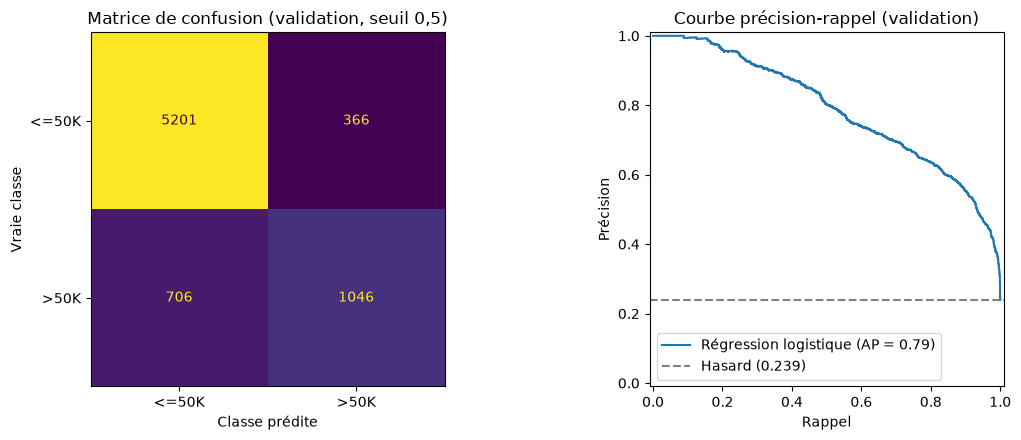

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_val, (proba_reference >= 0.5).astype(int), display_labels=["<=50K", ">50K"], ax=axes[0], colorbar=False
)
axes[0].set(title="Matrice de confusion (validation, seuil 0,5)", xlabel="Classe prédite", ylabel="Vraie classe")

PrecisionRecallDisplay.from_predictions(y_val, proba_reference, ax=axes[1], name="Régression logistique")
axes[1].axhline(y_val.mean(), linestyle="--", color="grey", label=f"Hasard ({y_val.mean():.3f})")
axes[1].set(title="Courbe précision-rappel (validation)", xlabel="Rappel", ylabel="Précision")
axes[1].legend()

plt.tight_layout()
plt.show()

Le modèle **classe bien** les personnes : PR-AUC de 0,788 contre 0,239 au hasard, ROC-AUC de 0,916. Mais au seuil de 0,5, il ne trouve que **1 046 des 1 752 `>50K`** de la validation : un **rappel de 59,7 %**, loin des 80 % visés. Il en rate 706, soit 4 sur 10.

C'est l'effet du déséquilibre : entraîné sur 76 % de `<=50K`, le modèle donne à beaucoup de vrais `>50K` une probabilité de 0,3 ou 0,4. Ils sont bien classés, mais pas assez haut pour franchir 0,5. En contrepartie, quand il contacte quelqu'un, il a souvent raison (précision de 74,1 %).

La courbe précision-rappel montre qu'un rappel de 80 % est atteignable avec ce même modèle : il faut descendre plus bas dans la liste, en acceptant une précision plus faible.

#### 3.3 Les trois remèdes

Chaque remède est évalué deux fois sur la validation : **au seuil de 0,5**, pour voir son effet brut, puis **au seuil qui donne 80 % de rappel**, pour une comparaison équitable. Notre objectif étant un rappel de 80 %, la vraie question est : à rappel égal, quel remède a la meilleure précision, c'est-à-dire contacte le moins de clients pour rien ?

**Remède 1 : ajuster le seuil.** On garde le même modèle et on change seulement la règle de décision : on cherche le seuil le plus élevé qui garde un rappel d'au moins 80 %. Le modèle n'est pas réentraîné, donc sa PR-AUC ne change pas.

In [46]:
from sklearn.metrics import precision_recall_curve

def seuil_pour_rappel(y_vrai, proba, rappel_min=0.80):
    """Seuil le plus élevé qui garde un rappel d'au moins rappel_min."""
    precisions, rappels, seuils = precision_recall_curve(y_vrai, proba)
    return seuils[rappels[:-1] >= rappel_min].max()

seuil_reference = seuil_pour_rappel(y_val, proba_reference)
resultats_desequilibre.append(evaluer("Référence, seuil ajusté", y_val, proba_reference, seuil_reference))
print(f"Seuil qui donne 80 % de rappel : {seuil_reference:.3f}")

Seuil qui donne 80 % de rappel : 0.305


**Remède 2 : pondérer les classes.** On réentraîne la régression logistique avec `class_weight="balanced"` : chaque erreur sur un `>50K` compte environ 3 fois plus dans la fonction de perte (76 / 24). Le modèle apprend à donner des probabilités plus élevées aux `>50K`. Contrairement au seuil, ce remède **change l'apprentissage**.

In [47]:
modele_pondere = Pipeline([
    ("preprocessing", construire_preprocessing()),
    ("modele", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
modele_pondere.fit(X_train, y_train)
proba_pondere = modele_pondere.predict_proba(X_val)[:, 1]

seuil_pondere = seuil_pour_rappel(y_val, proba_pondere)
resultats_desequilibre += [
    evaluer("Pondération des classes", y_val, proba_pondere),
    evaluer("Pondération des classes, seuil ajusté", y_val, proba_pondere, seuil_pondere),
]

**Remède 3 : SMOTE.** On ajoute au train des `>50K` artificiels, créés entre deux `>50K` proches, jusqu'à avoir autant de `>50K` que de `<=50K`. Ce remède **change les données d'entraînement**.

SMOTE doit être placé **dans le Pipeline**, après le prétraitement et avant le modèle. Ainsi, il n'est appliqué qu'aux données d'entraînement (`fit`), jamais à la validation ni au test (`predict`), qui gardent leur vraie répartition. L'appliquer avant le découpage serait une fuite. On utilise le `Pipeline` d'imbalanced-learn, car celui de scikit-learn n'accepte pas d'étape qui modifie le nombre de lignes.

Limite : après le one-hot, SMOTE crée des valeurs intermédiaires (par exemple 0,4 dans une colonne qui devrait valoir 0 ou 1), qui ne correspondent à aucune personne réelle. `SMOTENC` traite ce cas, mais nous restons sur SMOTE pour cette comparaison.

In [50]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImblearn

# Le Pipeline d'imbalanced-learn n'accepte pas un Pipeline comme étape : on déplie le prétraitement
modele_smote = PipelineImblearn([
    *construire_preprocessing().steps,
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("modele", LogisticRegression(max_iter=1000)),
])
modele_smote.fit(X_train, y_train)
proba_smote = modele_smote.predict_proba(X_val)[:, 1]

seuil_smote = seuil_pour_rappel(y_val, proba_smote)
resultats_desequilibre += [
    evaluer("SMOTE", y_val, proba_smote),
    evaluer("SMOTE, seuil ajusté", y_val, proba_smote, seuil_smote),
]
pd.DataFrame(resultats_desequilibre).round(3)

,modèle,seuil,PR-AUC,ROC-AUC,précision,rappel,F1
0,Référence,0.500,0.788,0.916,0.741,0.597,0.661
1,"Référence, seuil ajusté",0.305,0.788,0.916,0.636,0.800,0.709
2,Pondération des classes,0.500,0.786,0.916,0.589,0.861,0.699
3,"Pondération des classes, seuil ajusté",0.581,0.786,0.916,0.632,0.800,0.706
4,SMOTE,0.500,0.788,0.915,0.594,0.860,0.702
5,"SMOTE, seuil ajusté",0.577,0.788,0.915,0.632,0.800,0.706


#### 3.4 Comparaison et choix du remède

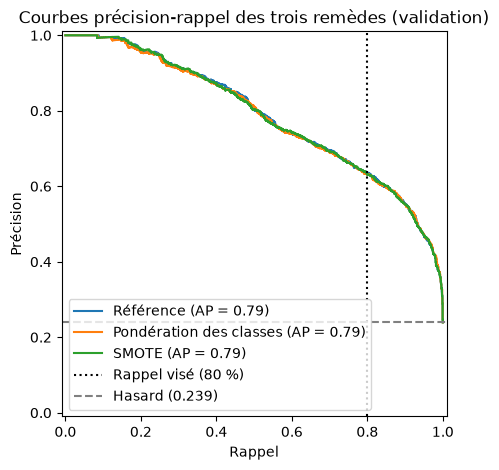

In [51]:
# Les courbes précision-rappel des trois modèles, avec le rappel visé
fig, ax = plt.subplots(figsize=(6.5, 5))
for nom, proba in [("Référence", proba_reference), ("Pondération des classes", proba_pondere), ("SMOTE", proba_smote)]:
    PrecisionRecallDisplay.from_predictions(y_val, proba, ax=ax, name=nom)
ax.axvline(0.80, linestyle=":", color="black", label="Rappel visé (80 %)")
ax.axhline(y_val.mean(), linestyle="--", color="grey", label=f"Hasard ({y_val.mean():.3f})")
ax.set(title="Courbes précision-rappel des trois remèdes (validation)", xlabel="Rappel", ylabel="Précision")
ax.legend()
plt.show()

In [52]:
from sklearn.metrics import brier_score_loss

# Les probabilités prédites sont-elles réalistes ? Comparaison avec la vraie part de >50K de la validation
pd.DataFrame({
    "probabilité moyenne prédite": [p.mean() for p in (proba_reference, proba_pondere, proba_smote)],
    "vraie part de >50K": y_val.mean(),
    "score de Brier": [brier_score_loss(y_val, p) for p in (proba_reference, proba_pondere, proba_smote)],
}, index=["Référence", "Pondération des classes", "SMOTE"]).round(3)

,probabilité moyenne prédite,vraie part de >50K,score de Brier
Référence,0.237,0.239,0.097
Pondération des classes,0.362,0.239,0.121
SMOTE,0.356,0.239,0.120


**Constats :**
- **La pondération et SMOTE n'améliorent pas le classement** : la PR-AUC reste à 0,786–0,788, et les trois courbes précision-rappel se superposent presque. Ces remèdes ne changent pas l'ordre des clients, seulement le niveau des probabilités : plus de personnes franchissent 0,5, d'où un rappel plus élevé à ce seuil (86 % au lieu de 60 %).
- **À rappel égal (80 %), les trois remèdes se valent** : précision de 0,636 pour le seuil ajusté, 0,632 pour la pondération et pour SMOTE.
- **La pondération et SMOTE déforment les probabilités** : le modèle apprend dans un monde artificiel à 50/50. Ses probabilités sont gonflées (0,36 en moyenne, pour une vraie part de 0,24) et son score de Brier se dégrade (0,121 contre 0,097 ; plus bas, c'est mieux). La référence prédit en moyenne 0,237, très proche de la réalité.

**Décision : on retient l'ajustement du seuil**, le remède le plus simple et le moins invasif. Il atteint l'objectif de 80 % de rappel sans réentraîner le modèle, sans créer de données artificielles, et en gardant des probabilités réalistes, ce qui compte pour la calibration (exigence 9).

Ce résultat est cohérent avec un déséquilibre **modéré** (24 % de positifs) : le modèle voit assez de `>50K` pour bien les classer, il suffit de régler le seuil de décision. Avec un déséquilibre extrême, comme la fraude à 0,17 %, la pondération ou SMOTE pourraient devenir utiles.

**Application :** les trois modèles de l'exigence 4 sont entraînés sans pondération ni SMOTE. Pour chacun, le seuil qui donne 80 % de rappel est choisi sur la validation avec `seuil_pour_rappel`, puis appliqué une seule fois au test.

## <span style="color: red;">4 - Progression de modélisation</span>

On compare trois modèles qui suivent la progression du cours, chacun corrigeant une faiblesse du précédent :
1. **Régression logistique** : simple, rapide et interprétable, mais limitée aux relations linéaires (d'où l'âge au carré et les logs créés en 2.3).
2. **Random Forest** : une moyenne de nombreux arbres construits indépendamment, qui trouvent seuls les seuils et les interactions entre variables.
3. **LightGBM** (gradient boosting) : des arbres construits l'un après l'autre, chacun corrigeant les erreurs des précédents.

Les trois modèles reçoivent **exactement le même prétraitement** (`construire_preprocessing()`) : seul l'estimateur change, la comparaison est donc équitable. Ils sont utilisés avec leurs **hyperparamètres par défaut** ; le réglage avec Optuna fait l'objet de l'exigence 6. Conformément à l'exigence 3, aucun n'utilise de pondération ni SMOTE.

#### 4.1 Les trois modèles

In [53]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

def construire_modele(estimateur):
    """Pipeline complet : le même prétraitement pour tous les modèles, suivi de l'estimateur."""
    return Pipeline([
        ("preprocessing", construire_preprocessing()),
        ("modele", estimateur),
    ])

modeles = {
    "Régression logistique": construire_modele(LogisticRegression(max_iter=1000)),
    "Random Forest": construire_modele(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    "LightGBM": construire_modele(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
}

#### 4.2 Validation croisée sur le train

Chaque modèle est évalué par validation croisée à 5 plis stratifiés sur le train : il est entraîné 5 fois sur 4/5 du train et évalué sur le 1/5 restant. La moyenne de la PR-AUC indique la performance, l'écart-type indique la **stabilité** du modèle d'un échantillon à l'autre. Le Pipeline réapprend tout le prétraitement dans chaque pli : aucune fuite.

In [54]:
from sklearn.model_selection import StratifiedKFold, cross_validate

validation_croisee = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

resultats_cv = []
for nom, modele in modeles.items():
    scores = cross_validate(modele, X_train, y_train, cv=validation_croisee, scoring="average_precision")
    resultats_cv.append({
        "modèle": nom,
        "PR-AUC moyenne": scores["test_score"].mean(),
        "écart-type": scores["test_score"].std(),
        "temps d'entraînement (s)": scores["fit_time"].mean(),
    })
pd.DataFrame(resultats_cv).set_index("modèle").round(3)

,PR-AUC moyenne,écart-type,temps d'entraînement (s)
modèle,,,
Régression logistique,0.782,0.006,0.367
Random Forest,0.757,0.010,0.717
LightGBM,0.830,0.006,0.308


- **LightGBM** est nettement le meilleur (PR-AUC de 0,830), tout en étant le plus rapide à entraîner. Construire les arbres séquentiellement, chacun corrigeant les erreurs des précédents, apporte un vrai gain : +0,048 par rapport à la régression logistique.
- **Le Random Forest par défaut fait moins bien que la régression logistique** (0,757 contre 0,782). Ce n'est pas une contradiction : avec ses réglages par défaut, chaque arbre pousse jusqu'à des feuilles d'une seule personne. Les arbres apprennent alors le bruit du train (forte variance, séance 3), et leurs probabilités sont trop tranchées, ce qui dégrade le classement. Le réglage de la profondeur et de la taille minimale des feuilles avec Optuna (exigence 6) devrait corriger cela.
- **La régression logistique** reste une référence solide, grâce aux variables créées en 2.3.
- Les écarts-types sont faibles (0,006 à 0,010) : les écarts entre modèles sont bien plus grands que la variabilité d'un pli à l'autre. Le classement est donc fiable.

#### 4.3 Comparaison sur la validation, au seuil qui donne 80 % de rappel

Chaque modèle est entraîné sur tout le train, puis évalué sur la validation avec les métriques du cadrage. Conformément à l'exigence 3, le seuil de chaque modèle est celui qui donne 80 % de rappel. À rappel égal, le meilleur modèle est celui qui contacte le moins de clients à tort.

In [55]:
resultats_modeles = []
probas_validation = {}

for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    proba = modele.predict_proba(X_val)[:, 1]
    probas_validation[nom] = proba

    seuil = seuil_pour_rappel(y_val, proba)
    resultat = evaluer(nom, y_val, proba, seuil)
    contacte = proba >= seuil
    resultat["clients contactés"] = contacte.sum()
    resultat["contactés à tort"] = (contacte & (y_val.to_numpy() == 0)).sum()
    resultats_modeles.append(resultat)

pd.DataFrame(resultats_modeles).set_index("modèle").round(3)

,seuil,PR-AUC,ROC-AUC,précision,rappel,F1,clients contactés,contactés à tort
modèle,,,,,,,,
Régression logistique,0.305,0.788,0.916,0.636,0.800,0.709,2204,802
Random Forest,0.270,0.753,0.900,0.600,0.802,0.687,2340,935
LightGBM,0.339,0.833,0.932,0.682,0.801,0.736,2058,655


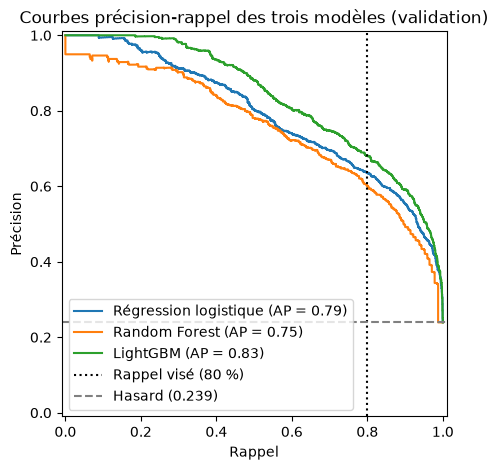

In [56]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for nom, proba in probas_validation.items():
    PrecisionRecallDisplay.from_predictions(y_val, proba, ax=ax, name=nom)
ax.axvline(0.80, linestyle=":", color="black", label="Rappel visé (80 %)")
ax.axhline(y_val.mean(), linestyle="--", color="grey", label=f"Hasard ({y_val.mean():.3f})")
ax.set(title="Courbes précision-rappel des trois modèles (validation)", xlabel="Rappel", ylabel="Précision")
ax.legend()
plt.show()

**Ce que chaque étape a apporté :**

| Étape | PR-AUC (validation) | Précision à 80 % de rappel | Contactés à tort | Lecture |
|---|---|---|---|---|
| Régression logistique | 0,788 | 0,636 | 802 | Référence solide, grâce aux variables créées en 2.3 |
| Random Forest (par défaut) | 0,753 | 0,600 | 935 | **Recul** : des arbres trop profonds apprennent le bruit du train |
| LightGBM (par défaut) | 0,833 | 0,682 | 655 | **Gain net** : les arbres successifs corrigent les erreurs des précédents |

- **Logistique → Random Forest** : capter seul les non-linéarités ne suffit pas si les arbres ne sont pas contrôlés. Sans limite de profondeur, chaque arbre mémorise le train (forte variance), et la moyenne de 100 arbres ne compense pas entièrement. Le Random Forest contacte 133 clients de plus à tort que la régression logistique.
- **Random Forest → LightGBM** : le boosting construit des arbres peu profonds, ajoutés un à un pour corriger les erreurs restantes. C'est le meilleur modèle sur toutes les métriques, et sa courbe précision-rappel est au-dessus des deux autres sur presque toute la plage.
- **Traduction pour la banque** : pour trouver le même nombre de clients `>50K` (80 %), LightGBM contacte 2 058 personnes, contre 2 204 pour la régression logistique, soit **147 contacts inutiles en moins** (655 contre 802).

Les résultats de validation confirment ceux de la validation croisée sur le train (même classement, mêmes ordres de grandeur). Ces modèles utilisent encore leurs hyperparamètres par défaut : l'exigence 6 les réglera avec Optuna, en particulier le Random Forest, dont la profondeur des arbres est en cause.

## <span style="color: red;">5 - Pipeline</span>

Tout le prétraitement et le modèle sont déjà regroupés dans un seul `Pipeline`, construit par `construire_modele()` :

1. `nouvelles_variables` : création de `age_carre`, `a_des_placements`, `log_capital_gain` et `log_capital_loss` (2.3) ;
2. `traitement_colonnes` : un `ColumnTransformer` qui envoie les catégorielles vers l'imputation `Unknown` et le one-hot (2.1, 2.2), et les numériques vers l'imputation par la médiane et la standardisation (2.4). Les autres colonnes sont ignorées ;
3. `modele` : l'estimateur (régression logistique, Random Forest ou LightGBM).

Ce regroupement garantit trois choses :
- **pas de fuite** : en validation croisée, tout le prétraitement est réappris dans chaque pli, sur les données d'entraînement uniquement ;
- **la reproductibilité** : les règles apprises (modalités connues, médianes, moyennes, écarts-types) sont stockées dans l'objet, et non dans des cellules du notebook ;
- **le déploiement** : l'API n'aura qu'à appeler `predict_proba` sur les données brutes d'un client.

Ci-dessous, le Pipeline du LightGBM (cliquer sur les blocs pour les déplier).

In [57]:
modeles["LightGBM"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('modele', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital-loss','hours-per-week', 'native-country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('nouvelles_variables', ...), ('traitement_colonnes', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given t

**Test 1 : prédire sur des données brutes, comme l'API.** On simule deux clients saisis à la main, avec seulement les colonnes utiles au modèle (sans `fnlwgt`, `education`, `sex` ni `race`). Le premier vient d'un pays absent des données (le Brésil). Le second a une catégorie d'emploi et une profession non renseignées.

In [58]:
clients = pd.DataFrame([
    {"age": 45, "workclass": "Private", "education-num": 13, "marital-status": "Married-civ-spouse",
     "occupation": "Exec-managerial", "relationship": "Husband", "capital-gain": 0, "capital-loss": 0,
     "hours-per-week": 50, "native-country": "Brazil"},
    {"age": 23, "workclass": None, "education-num": 9, "marital-status": "Never-married",
     "occupation": None, "relationship": "Own-child", "capital-gain": 0, "capital-loss": 0,
     "hours-per-week": 20, "native-country": "United-States"},
])
clients.assign(probabilite_50K=modeles["LightGBM"].predict_proba(clients)[:, 1].round(3))

,age,workclass,education-num,marital-status,occupation,relationship,capital-gain,capital-loss,hours-per-week,native-country,probabilite_50K
0,45,Private,13,Married-civ-spouse,Exec-managerial,Husband,0,0,50,Brazil,0.802
1,23,NaN,9,Never-married,NaN,Own-child,0,0,20,United-States,0.002


Le Pipeline prédit sans erreur : le pays inconnu est rangé dans le groupe des modalités rares. Les valeurs non renseignées sont acceptées : pour les reconnaître comme manquantes (None envoyé par une saisie, et pas seulement NaN), creer_variables les convertit en NaN, et elles deviennent alors Unknown. Les probabilités sont cohérentes : un cadre marié de 45 ans, diplômé et travaillant 50 h par semaine, est très probablement `>50K` ; un jeune de 23 ans vivant chez ses parents et travaillant 20 h ne l'est presque certainement pas.

**Test 2 : sauvegarder et recharger le Pipeline.** C'est ce fichier que l'API chargera au démarrage.

In [59]:
import joblib
from pathlib import Path

Path("modeles").mkdir(exist_ok=True)
joblib.dump(modeles["LightGBM"], "modeles/lightgbm_defaut.joblib")

modele_recharge = joblib.load("modeles/lightgbm_defaut.joblib")
proba_rechargee = modele_recharge.predict_proba(X_val)[:, 1]
print("Prédictions identiques après rechargement :", np.allclose(proba_rechargee, probas_validation["LightGBM"]))

Prédictions identiques après rechargement : True


## <span style="color: red;">6 - Réglage des hyperparamètres</span>

Chaque modèle est réglé avec Optuna : à chaque essai, Optuna propose une combinaison d'hyperparamètres, le Pipeline complet est évalué par **validation croisée à 5 plis sur le train** (PR-AUC moyenne), et Optuna utilise ce score pour orienter les essais suivants (échantillonneur TPE).

**Pourquoi le score rapporté n'est pas optimiste :** le meilleur score de validation croisée est optimiste, puisqu'on a retenu la combinaison qui a eu le meilleur résultat sur ces plis parmi des dizaines d'essais. On ne le présente donc pas comme la performance du modèle. Le modèle réglé est réentraîné sur tout le train, puis évalué sur la **validation**, qu'Optuna n'a jamais vue ; le test reste réservé à l'évaluation finale.

Pour ne lancer le réglage qu'une fois, chaque essai est **enregistré dans MLflow au moment où il est fait** (exigence 7, détaillée dans la partie 7).

#### 6.1 Mise en place du suivi MLflow

In [60]:
import mlflow
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)  # n'affiche pas une ligne par essai

# Les expériences sont enregistrées dans une base locale (mlflow.db), dans le dossier du projet
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("census-income")

c:\Users\jerem\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/18 18:31:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 18:31:59 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 18:32:02 INFO mlflow.tracking.fluent: Experiment with name 'census-income' does not exist. Creating a new experiment.


<Experiment: artifact_location=('file:c:/Users/jerem/OneDrive/Desktop/AlbertSchool/bootcamp_M2/Supervised '
 'Learning & Model Engineering/Projet_Solo/mlruns/1'), creation_time=1792341122215, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792341122215, lifecycle_stage='active', name='census-income', tags={}, trace_location=None, workspace='default'>

#### 6.2 Les espaces de recherche

Pour chaque modèle, on indique à Optuna quels hyperparamètres régler et dans quelles plages :

| Modèle | Hyperparamètre | Plage | Ce qu'il contrôle |
|---|---|---|---|
| Régression logistique | `C` | 0,001 à 100 (échelle log) | Force de la régularisation : petit `C` = forte pénalité |
| Random Forest | `n_estimators` | 100 à 300 | Nombre d'arbres |
| | `max_depth` | 4 à 30 | Profondeur maximale des arbres |
| | `min_samples_leaf` | 1 à 50 | Taille minimale d'une feuille : empêche les feuilles d'une seule personne |
| | `max_features` | `sqrt`, 30 %, 50 % | Part des variables testées à chaque coupure : diversité des arbres |
| LightGBM | `n_estimators` | 100 à 800 | Nombre de corrections successives |
| | `learning_rate` | 0,01 à 0,2 (log) | Taille de chaque correction |
| | `num_leaves` | 15 à 127 | Complexité de chaque arbre |
| | `min_child_samples` | 10 à 100 | Taille minimale d'une feuille |
| | `subsample`, `colsample_bytree` | 0,6–1 et 0,5–1 | Part des lignes et des colonnes utilisées par arbre |
| | `reg_lambda` | 0,001 à 10 (log) | Régularisation L2 des feuilles |

L'échelle logarithmique sert aux hyperparamètres dont l'effet dépend de l'ordre de grandeur : passer de 0,001 à 0,01 compte autant que passer de 10 à 100.

In [61]:
def proposer_estimateur(trial, nom):
    """Crée l'estimateur avec les hyperparamètres proposés par Optuna pour cet essai."""
    if nom == "Régression logistique":
        return LogisticRegression(C=trial.suggest_float("C", 1e-3, 1e2, log=True), max_iter=2000)
    if nom == "Random Forest":
        return RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            max_depth=trial.suggest_int("max_depth", 4, 30),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50, log=True),
            max_features=trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
            random_state=RANDOM_STATE, n_jobs=-1,
        )
    return LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 127, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 100, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        random_state=RANDOM_STATE, verbose=-1,
    )

#### 6.3 Lancement du réglage

Pour chaque modèle, une « étude » Optuna est enregistrée dans MLflow comme une exécution parente, et chaque essai comme une exécution enfant, avec ses hyperparamètres et sa PR-AUC de validation croisée. La graine de l'échantillonneur est fixée pour la reproductibilité. Budget : 30 essais pour la régression logistique et le Random Forest, 50 pour LightGBM, qui a le plus d'hyperparamètres (environ 10 minutes au total).

In [62]:
from sklearn.model_selection import cross_val_score

def regler(nom, n_essais):
    """Règle un modèle avec Optuna et enregistre chaque essai dans MLflow."""
    def objectif(trial):
        modele = construire_modele(proposer_estimateur(trial, nom))
        scores = cross_val_score(modele, X_train, y_train, cv=validation_croisee, scoring="average_precision")
        with mlflow.start_run(run_name=f"{nom} - essai {trial.number}", nested=True):
            mlflow.log_params(trial.params)
            mlflow.log_metrics({"pr_auc_cv": scores.mean(), "pr_auc_cv_ecart_type": scores.std()})
        return scores.mean()

    with mlflow.start_run(run_name=f"Optuna - {nom}"):
        etude = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
        etude.optimize(objectif, n_trials=n_essais)
        mlflow.log_params(etude.best_params)
        mlflow.log_metric("meilleure_pr_auc_cv", etude.best_value)
    return etude

budgets = {"Régression logistique": 30, "Random Forest": 30, "LightGBM": 50}
etudes = {}
for nom, n_essais in budgets.items():
    etudes[nom] = regler(nom, n_essais)
    print(f"{nom} : meilleure PR-AUC en validation croisée = {etudes[nom].best_value:.4f}")

Régression logistique : meilleure PR-AUC en validation croisée = 0.7842
Random Forest : meilleure PR-AUC en validation croisée = 0.8150
LightGBM : meilleure PR-AUC en validation croisée = 0.8335


In [63]:
# Meilleurs hyperparamètres trouvés pour chaque modèle
for nom, etude in etudes.items():
    print(f"{nom} : {etude.best_params}")

Régression logistique : {'C': 31.684303145302987}
Random Forest : {'n_estimators': 150, 'max_depth': 14, 'min_samples_leaf': 2, 'max_features': 0.3}
LightGBM : {'n_estimators': 600, 'learning_rate': 0.023023710609724087, 'num_leaves': 32, 'min_child_samples': 10, 'subsample': 0.9117836128199638, 'colsample_bytree': 0.5094196420661883, 'reg_lambda': 0.04902951156241922}


#### 6.4 Évaluation des modèles réglés sur la validation

Chaque modèle est réentraîné sur tout le train avec ses meilleurs hyperparamètres, puis évalué sur la validation, qu'Optuna n'a jamais vue, au seuil qui donne 80 % de rappel. Chaque modèle final est enregistré dans MLflow avec ses hyperparamètres, ses métriques de validation et deux artefacts : sa courbe précision-rappel et le fichier du Pipeline entraîné.

In [64]:
FICHIERS = {"Régression logistique": "regression_logistique", "Random Forest": "random_forest", "LightGBM": "lightgbm"}

modeles_regles, probas_regles, resultats_regles = {}, {}, []
for nom, etude in etudes.items():
    # Même fonction qu'en 6.2, avec les meilleurs hyperparamètres « figés »
    modele = construire_modele(proposer_estimateur(optuna.trial.FixedTrial(etude.best_params), nom))
    modele.fit(X_train, y_train)
    proba = modele.predict_proba(X_val)[:, 1]
    seuil = seuil_pour_rappel(y_val, proba)

    resultat = evaluer(f"{nom} (réglé)", y_val, proba, seuil)
    resultat["contactés à tort"] = ((proba >= seuil) & (y_val.to_numpy() == 0)).sum()
    resultats_regles.append(resultat)
    modeles_regles[nom], probas_regles[nom] = modele, proba

    # Enregistrement dans MLflow : hyperparamètres, métriques de validation et artefacts
    with mlflow.start_run(run_name=f"Final - {nom}"):
        mlflow.log_params(etude.best_params)
        mlflow.log_metrics({
            "pr_auc_cv": etude.best_value, "pr_auc_val": resultat["PR-AUC"], "roc_auc_val": resultat["ROC-AUC"],
            "precision_val": resultat["précision"], "rappel_val": resultat["rappel"], "f1_val": resultat["F1"],
            "seuil": seuil, "contactes_a_tort_val": resultat["contactés à tort"],
        })
        fig, ax = plt.subplots(figsize=(5, 4))
        PrecisionRecallDisplay.from_predictions(y_val, proba, ax=ax, name=nom)
        mlflow.log_figure(fig, "courbe_precision_rappel.png")
        plt.close(fig)
        chemin = f"modeles/{FICHIERS[nom]}_regle.joblib"
        joblib.dump(modele, chemin)
        mlflow.log_artifact(chemin)

pd.DataFrame(resultats_regles).set_index("modèle").round(3)

,seuil,PR-AUC,ROC-AUC,précision,rappel,F1,contactés à tort
modèle,,,,,,,
Régression logistique (réglé),0.301,0.790,0.916,0.634,0.8,0.708,809
Random Forest (réglé),0.325,0.818,0.924,0.660,0.8,0.723,723
LightGBM (réglé),0.339,0.835,0.932,0.686,0.8,0.739,642


In [65]:
# Avant / après réglage, et score de validation croisée d'Optuna face au score de validation
pd.DataFrame({
    "PR-AUC CV (défaut)": [r["PR-AUC moyenne"] for r in resultats_cv],
    "PR-AUC CV (meilleur essai)": [etude.best_value for etude in etudes.values()],
    "PR-AUC validation (défaut)": [r["PR-AUC"] for r in resultats_modeles],
    "PR-AUC validation (réglé)": [r["PR-AUC"] for r in resultats_regles],
    "contactés à tort (défaut)": [r["contactés à tort"] for r in resultats_modeles],
    "contactés à tort (réglé)": [r["contactés à tort"] for r in resultats_regles],
}, index=list(etudes)).round(3)

,PR-AUC CV (défaut),PR-AUC CV (meilleur essai),PR-AUC validation (défaut),PR-AUC validation (réglé),contactés à tort (défaut),contactés à tort (réglé)
Régression logistique,0.782,0.784,0.788,0.790,802,809
Random Forest,0.757,0.815,0.753,0.818,935,723
LightGBM,0.830,0.834,0.833,0.835,655,642


**Ce que le réglage a apporté (validation, 80 % de rappel) :**
- **Random Forest** : le grand gagnant. La PR-AUC passe de 0,753 à 0,818, et le nombre de clients contactés à tort de 935 à 723. Optuna a limité la profondeur des arbres (`max_depth` = 14) et réduit la part de variables testées à chaque coupure (`max_features` = 30 %). C'est la correction du surapprentissage identifié à l'exigence 4.
- **LightGBM** : un gain faible (PR-AUC de 0,833 à 0,835, 655 à 642 contactés à tort) : ses réglages par défaut étaient déjà bons. Optuna a choisi plus d'arbres (600) avec des corrections plus petites (`learning_rate` = 0,023), le compromis classique du boosting.
- **Régression logistique** : aucun gain réel (0,788 à 0,790). Optuna a choisi un `C` élevé (31,7), c'est-à-dire une régularisation faible : avec 34 152 lignes pour 66 colonnes, le modèle risque peu le surapprentissage, la régularisation n'est donc pas nécessaire.

**LightGBM reste le meilleur modèle** : meilleure PR-AUC (0,835), meilleure précision à 80 % de rappel (0,686) et le moins de clients contactés à tort (642). C'est notre modèle final.

**Optimisme du score de validation croisée :** le meilleur score d'Optuna devait, en principe, surestimer la performance. Ici, l'écart avec la validation est négligeable (0,834 en validation croisée contre 0,835 en validation pour LightGBM), et du même ordre que l'écart-type entre plis (environ 0,006). Avec 34 152 lignes et un nombre d'essais modéré, le biais de sélection reste faible. Ce n'était pas garanti à l'avance, d'où l'importance de l'avoir vérifié sur des données non vues.

## <span style="color: red;">7 - Suivi des expériences</span>

#### 7.1 Suivi des expériences avec MLflow

MLflow enregistre chaque entraînement comme une **exécution** (*run*), avec ses **paramètres** (hyperparamètres), ses **métriques** (PR-AUC, précision, rappel…) et ses **artefacts** (courbe précision-rappel, fichier du modèle). On peut ainsi retrouver, comparer et recharger n'importe quel essai.

Trois familles d'exécutions sont enregistrées dans l'expérience `census-income` :
- **`Optuna - <modèle>`** (6.3) : une exécution par étude, contenant une exécution enfant par essai (110 au total), avec les hyperparamètres testés et la PR-AUC de validation croisée ;
- **`Final - <modèle>`** (6.4) : les modèles réglés, avec leurs métriques de validation, leur courbe précision-rappel et le fichier du Pipeline ;
- **`Défaut - <modèle>`** (ci-dessous) : les trois modèles de l'exigence 4, avec leurs hyperparamètres par défaut, pour garder la trace du point de départ.

In [66]:
# Enregistrement des trois modèles par défaut de l'exigence 4
for (nom, modele), res_cv, res_val in zip(modeles.items(), resultats_cv, resultats_modeles):
    with mlflow.start_run(run_name=f"Défaut - {nom}"):
        mlflow.log_params(modele.named_steps["modele"].get_params())
        mlflow.log_metrics({
            "pr_auc_cv": res_cv["PR-AUC moyenne"], "pr_auc_cv_ecart_type": res_cv["écart-type"],
            "pr_auc_val": res_val["PR-AUC"], "roc_auc_val": res_val["ROC-AUC"],
            "precision_val": res_val["précision"], "rappel_val": res_val["rappel"], "f1_val": res_val["F1"],
            "seuil": res_val["seuil"], "contactes_a_tort_val": res_val["contactés à tort"],
        })
        fig, ax = plt.subplots(figsize=(5, 4))
        PrecisionRecallDisplay.from_predictions(y_val, probas_validation[nom], ax=ax, name=nom)
        mlflow.log_figure(fig, "courbe_precision_rappel.png")
        plt.close(fig)

#### 7.2 Consulter les exécutions

Les exécutions peuvent être relues directement depuis Python : ci-dessous, les six modèles (par défaut et réglés), triés par PR-AUC de validation.

In [67]:
runs = mlflow.search_runs(experiment_names=["census-income"])
runs = runs[runs["tags.mlflow.runName"].str.startswith(("Défaut", "Final"))]

colonnes = {"tags.mlflow.runName": "exécution", "metrics.pr_auc_cv": "PR-AUC CV",
            "metrics.pr_auc_val": "PR-AUC validation", "metrics.precision_val": "précision",
            "metrics.rappel_val": "rappel", "metrics.contactes_a_tort_val": "contactés à tort"}
runs[list(colonnes)].rename(columns=colonnes).sort_values("PR-AUC validation", ascending=False).round(3)

,exécution,PR-AUC CV,PR-AUC validation,précision,rappel,contactés à tort
3,Final - LightGBM,0.834,0.835,0.686,0.800,642.0
0,Défaut - LightGBM,0.830,0.833,0.682,0.801,655.0
4,Final - Random Forest,0.815,0.818,0.660,0.800,723.0
5,Final - Régression logistique,0.784,0.790,0.634,0.800,809.0
2,Défaut - Régression logistique,0.782,0.788,0.636,0.800,802.0
1,Défaut - Random Forest,0.757,0.753,0.600,0.802,935.0


C:\Users\jerem\AppData\Local\Temp\ipykernel_22448\436531574.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(etudes["LightGBM"])


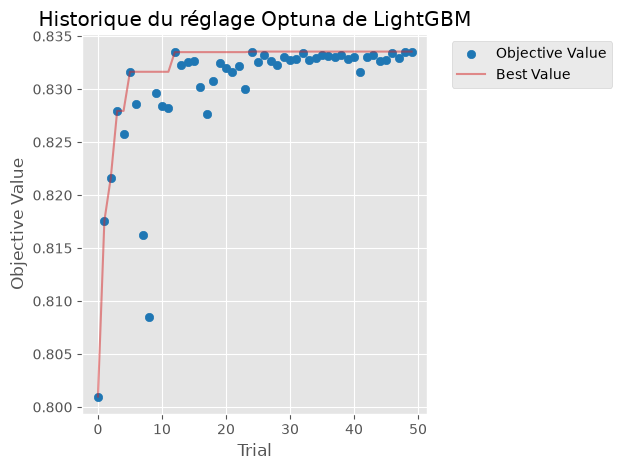

In [68]:
# Historique du réglage de LightGBM : score de chaque essai et meilleur score atteint
optuna.visualization.matplotlib.plot_optimization_history(etudes["LightGBM"])
plt.title("Historique du réglage Optuna de LightGBM")
plt.show()

Chaque point est un essai et la ligne rouge le meilleur score atteint. Les premiers essais explorent au hasard ; ensuite, l'échantillonneur TPE se concentre sur les zones prometteuses et le meilleur score progresse, puis se stabilise : un budget plus grand n'apporterait probablement qu'un gain marginal.

**Interface MLflow :** l'interface web permet de parcourir toutes les exécutions, de les trier, de comparer leurs hyperparamètres et d'ouvrir les artefacts. Elle se lance depuis un terminal, dans le dossier du projet, avec la commande `python -m mlflow ui --backend-store-uri sqlite:///mlflow.db`, puis s'ouvre à l'adresse http://127.0.0.1:5000.

## <span style="color: red;">8 - Explicabilité</span>

On explique le **modèle final**, le LightGBM réglé (6.4). Pour une prédiction, SHAP répartit l'écart entre la prédiction moyenne et la prédiction de la personne entre ses variables : chaque variable reçoit une contribution positive (elle pousse vers `>50K`) ou négative. La moyenne des contributions absolues sur de nombreuses personnes donne l'importance globale.

Deux précautions :
- pour LightGBM, les contributions sont exprimées en **log-odds** (l'échelle avant la sigmoïde), pas en probabilités ;
- SHAP explique **le comportement du modèle**, pas la réalité : une contribution positive n'est pas une preuve de causalité.

SHAP s'applique au LightGBM seul : on lui fournit un échantillon de 2 000 personnes de la validation, transformées par le Pipeline. Pour la lisibilité, les variables numériques sont affichées dans leur unité d'origine (âge en années, etc.).

#### 8.1 Importance globale

In [69]:
import shap

# Modèle final : le LightGBM réglé (6.4), avec son seuil à 80 % de rappel sur la validation
modele_final = modeles_regles["LightGBM"]
proba_final = probas_regles["LightGBM"]
SEUIL_FINAL = seuil_pour_rappel(y_val, proba_final)

# SHAP s'applique au LightGBM seul : on lui donne les données déjà transformées par le Pipeline
etape_variables = modele_final.named_steps["preprocessing"].named_steps["nouvelles_variables"]
etape_colonnes = modele_final.named_steps["preprocessing"].named_steps["traitement_colonnes"]
lgbm = modele_final.named_steps["modele"]

echantillon = X_val.sample(2000, random_state=RANDOM_STATE)
X_transforme = etape_colonnes.transform(etape_variables.transform(echantillon))
noms = [nom.split("__", 1)[1] for nom in etape_colonnes.get_feature_names_out()]  # retire « numeriques__ »

# Pour des graphiques lisibles, on affiche les numériques dans leur unité d'origine
X_lisible = pd.DataFrame(X_transforme, columns=noms, index=echantillon.index)
standardisation = etape_colonnes.named_transformers_["numeriques"].named_steps["mise_a_echelle"]
X_lisible[COLONNES_NUMERIQUES] = standardisation.inverse_transform(X_lisible[COLONNES_NUMERIQUES])

explication = shap.TreeExplainer(lgbm)(X_transforme)
explication.data = X_lisible.to_numpy()
explication.feature_names = noms

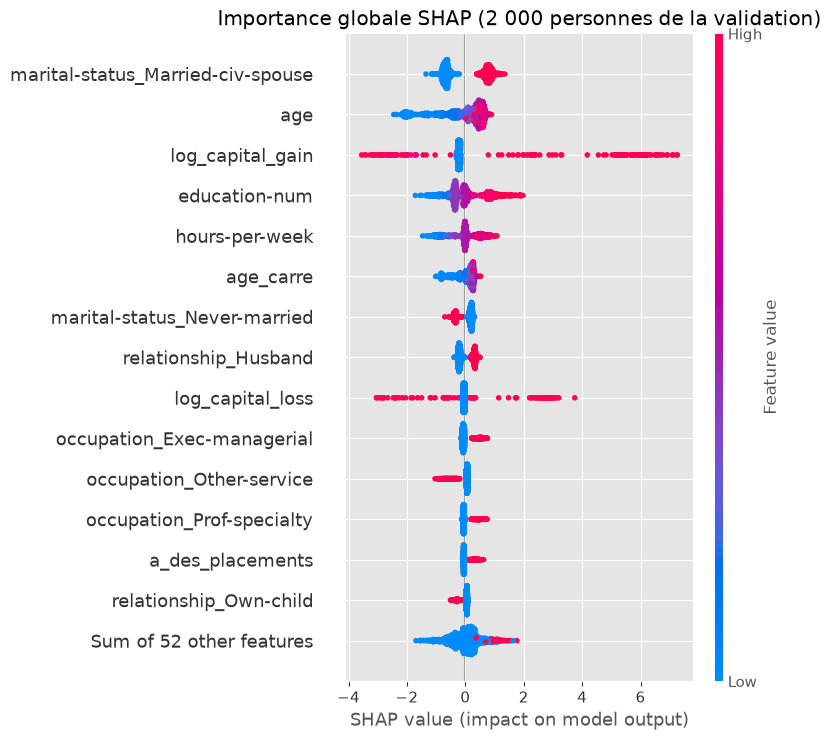

In [70]:
shap.plots.beeswarm(explication, max_display=15, show=False)
plt.title("Importance globale SHAP (2 000 personnes de la validation)")
plt.tight_layout()
plt.show()

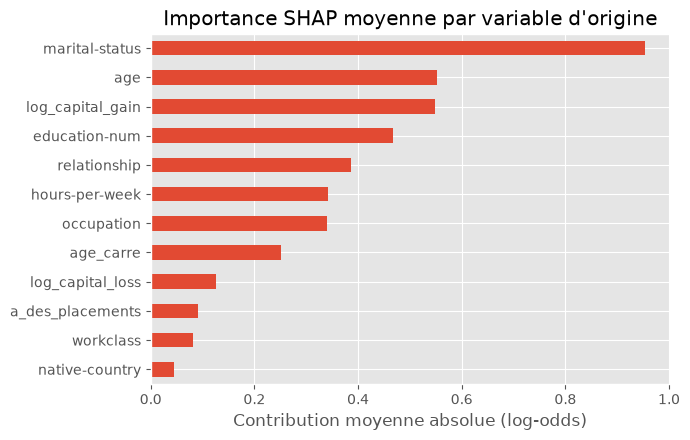

In [71]:
# Importance par variable d'origine : on additionne les contributions des colonnes one-hot d'une même variable
variable_origine = {nom: next((c for c in COLONNES_CATEGORIELLES if nom.startswith(c + "_")), nom) for nom in noms}
contributions = pd.DataFrame(explication.values, columns=noms).T.groupby(variable_origine).sum().T
importance = contributions.abs().mean().sort_values()

importance.plot.barh(figsize=(7, 4.5), title="Importance SHAP moyenne par variable d'origine")
plt.xlabel("Contribution moyenne absolue (log-odds)")
plt.tight_layout()
plt.show()

**Lecture du beeswarm :** chaque point est une personne. Sa position horizontale est la contribution de la variable à sa prédiction, sa couleur la valeur de la variable (rouge = élevée, bleu = faible).

**Les variables les plus importantes et leur sens métier :**
- **`marital-status`** (de loin la première, 0,95) : être marié (`Married-civ-spouse`) pousse fortement vers `>50K`, ne jamais avoir été marié pousse vers `<=50K`. Le mariage est associé à la stabilité professionnelle et à l'âge. Attention : le revenu du recensement est **individuel**, mais la situation de couple reste très liée au niveau de vie.
- **`age`** (0,55) : les plus jeunes ont des contributions très négatives (début de carrière). Avec `age_carre`, le modèle reproduit la courbe en cloche vue en 2.3.
- **`log_capital_gain`** (0,55) : les gros gains en capital poussent très fortement vers `>50K` (jusqu'à +6), car ils signalent un patrimoine. On voit aussi des points rouges à gauche : les **petits** gains (moins de 5 000) font baisser la prédiction. C'est cohérent avec l'EDA, où ces personnes n'étaient que 18 % en `>50K`.
- **`education-num`** (0,47) : plus le niveau d'études est élevé, plus la prédiction monte, ce qui est attendu.
- **`relationship`** (0,39) et **`hours-per-week`** (0,34) : le statut de `Husband` pousse vers `>50K`, tout comme un temps de travail élevé.

**Point d'attention pour l'équité :** `relationship_Husband` fait partie des variables importantes. Or cette modalité désigne presque toujours un homme : c'est le **proxy du sexe** identifié dans le cadrage. Bien que `sex` ne soit pas une variable du modèle, celui-ci s'appuie en partie sur une information qui la reconstruit. L'audit d'équité (exigence 10) mesurera l'effet de ce proxy.

#### 8.2 Explications locales

On explique trois prédictions de l'échantillon, au seuil final (80 % de rappel) : le client `>50K` détecté avec le plus de certitude, le client `>50K` raté le plus nettement, et le client `<=50K` contacté à tort avec le plus de certitude. Les cas d'erreur sont les plus instructifs pour comprendre les limites du modèle.

In [72]:
proba_echantillon = modele_final.predict_proba(echantillon)[:, 1]
y_echantillon = y_val.loc[echantillon.index].to_numpy()
contacte = proba_echantillon >= SEUIL_FINAL

vrais_positifs = np.where((y_echantillon == 1) & contacte)[0]
faux_negatifs = np.where((y_echantillon == 1) & ~contacte)[0]
faux_positifs = np.where((y_echantillon == 0) & contacte)[0]
cas = {
    "Vrai positif (le plus sûr)": vrais_positifs[proba_echantillon[vrais_positifs].argmax()],
    "Faux négatif (le plus net)": faux_negatifs[proba_echantillon[faux_negatifs].argmin()],
    "Faux positif (le plus sûr)": faux_positifs[proba_echantillon[faux_positifs].argmax()],
}

positions = list(cas.values())
colonnes_profil = ["age", "workclass", "education", "marital-status", "occupation",
                   "relationship", "sex", "capital-gain", "hours-per-week"]
profils = echantillon.iloc[positions][colonnes_profil].assign(
    probabilite=proba_echantillon[positions].round(3), vraie_classe=y_echantillon[positions]
)
profils.index = list(cas)
profils

,age,workclass,education,marital-status,occupation,relationship,sex,capital-gain,hours-per-week,probabilite,vraie_classe
Vrai positif (le plus sûr),54,Self-emp-inc,Prof-school,Married-civ-spouse,Prof-specialty,Husband,Male,99999,40,0.999,1
Faux négatif (le plus net),20,Private,12th,Never-married,Other-service,Own-child,Male,0,35,0.000,1
Faux positif (le plus sûr),33,Private,HS-grad,Married-civ-spouse,Exec-managerial,Husband,Male,4386,60,0.923,0


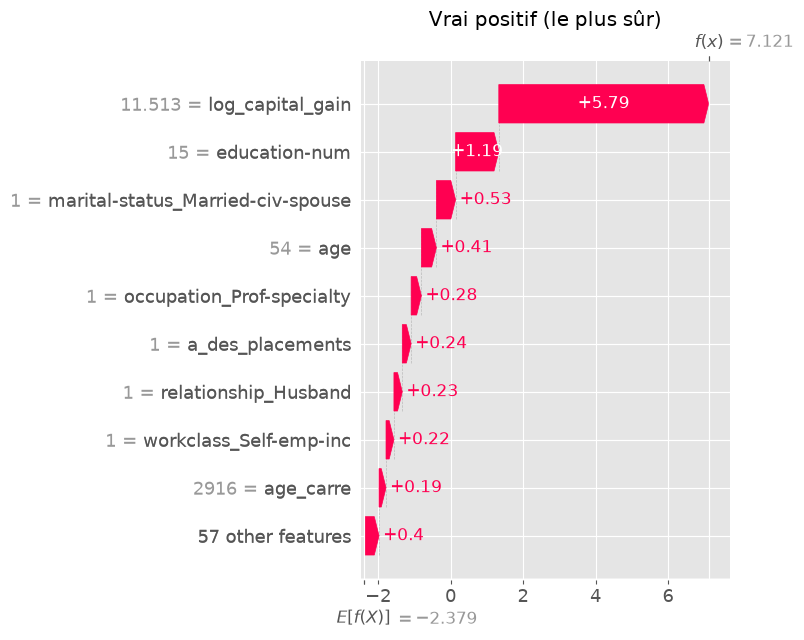

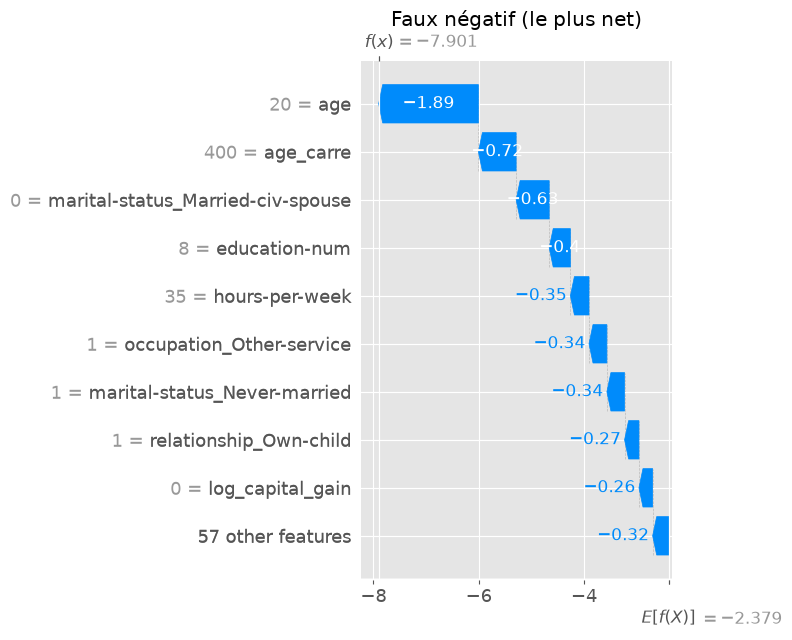

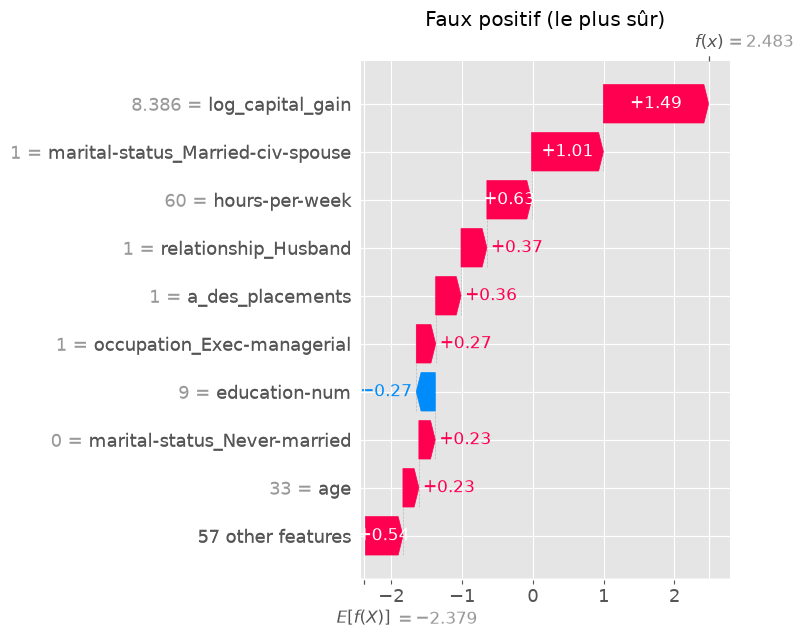

In [73]:
for titre, position in cas.items():
    shap.plots.waterfall(explication[position], max_display=10, show=False)
    plt.title(titre)
    plt.tight_layout()
    plt.show()

**Lecture d'un waterfall :** on part de la prédiction moyenne $E[f(X)]$ (−2,38 en log-odds, soit environ 8,5 %) en bas, et chaque barre ajoute la contribution d'une variable (rouge = vers `>50K`, bleu = vers `<=50K`), jusqu'à la prédiction de la personne $f(x)$ en haut.

1. **Vrai positif (probabilité 0,999)** : un homme de 54 ans, indépendant, diplômé d'une école professionnelle (`Prof-school`), marié, avec un gain en capital de 99 999. Le gain en capital explique l'essentiel (+5,8), complété par le niveau d'études (+1,2) et le mariage (+0,5). Un cas d'école.
2. **Faux négatif (probabilité quasi nulle)** : un jeune homme de 20 ans, niveau 12th, célibataire, vivant chez ses parents (`Own-child`), employé dans les services, 35 h par semaine, et pourtant `>50K`. Tous ses attributs poussent vers `<=50K`, l'âge en premier (−1,9). Aucune information disponible ne permettait de le détecter : c'est un profil atypique, voire une erreur de saisie dans la cible. Le modèle ne peut pas trouver ce que les variables ne contiennent pas.
3. **Faux positif (probabilité 0,923)** : un homme de 33 ans, marié, cadre (`Exec-managerial`), 60 h par semaine, avec un gain en capital de 4 386, mais `<=50K`. Le gain en capital (+1,5), le mariage (+1,0) et les heures (+0,6) ressemblent à ceux des hauts revenus. Ce profil est « logiquement » un client à contacter : pour la banque, c'est une erreur peu coûteuse, et ce client est peut-être sur le point de dépasser les 50 K$.

#### 8.3 Diagnostic par segment

Un bon score global peut cacher un segment où le modèle échoue. On recalcule les métriques par groupe sur toute la validation, au seuil final. Pour chaque groupe, on affiche aussi l'**effectif** (un petit groupe donne des chiffres bruités) et la **part de `>50K`** (la PR-AUC en dépend fortement, ce qui rend les comparaisons délicates). Le segment le plus faible est défini avec la métrique qui compte pour notre cas d'usage : le **rappel**.

In [74]:
def evaluer_tranches(groupes):
    """Métriques du modèle final par groupe, sur la validation, au seuil final."""
    proba = pd.Series(proba_final, index=X_val.index)
    lignes = []
    for groupe, index in X_val.groupby(groupes, observed=True).groups.items():
        y_groupe, proba_groupe = y_val.loc[index], proba.loc[index]
        contacte = proba_groupe >= SEUIL_FINAL
        lignes.append({
            "groupe": groupe,
            "effectif": len(index),
            "dont >50K": y_groupe.sum(),
            "part de >50K": y_groupe.mean(),
            "PR-AUC": average_precision_score(y_groupe, proba_groupe),
            "précision": precision_score(y_groupe, contacte, zero_division=0),
            "rappel": recall_score(y_groupe, contacte),
        })
    return pd.DataFrame(lignes).set_index("groupe").round(3)

tranches_age_val = pd.cut(X_val["age"], [16, 25, 35, 45, 55, 65, 90])
for titre, groupes in [("Âge", tranches_age_val), ("Sexe", X_val["sex"]), ("Race", X_val["race"])]:
    print(titre)
    display(evaluer_tranches(groupes))

Âge


,effectif,dont >50K,part de >50K,PR-AUC,précision,rappel
groupe,,,,,,
"(16, 25]",1458,21,0.014,0.502,0.700,0.333
"(25, 35]",1933,368,0.190,0.788,0.679,0.707
"(35, 45]",1770,618,0.349,0.841,0.681,0.827
"(45, 55]",1244,487,0.391,0.870,0.694,0.873
"(55, 65]",669,207,0.309,0.818,0.674,0.787
"(65, 90]",245,51,0.208,0.858,0.766,0.706


Sexe


,effectif,dont >50K,part de >50K,PR-AUC,précision,rappel
groupe,,,,,,
Female,2402,246,0.102,0.807,0.701,0.772
Male,4917,1506,0.306,0.839,0.684,0.805


Race


,effectif,dont >50K,part de >50K,PR-AUC,précision,rappel
groupe,,,,,,
Amer-Indian-Eskimo,63,3,0.048,1.000,0.300,1.000
Asian-Pac-Islander,231,52,0.225,0.857,0.638,0.846
Black,721,85,0.118,0.791,0.674,0.729
Other,64,11,0.172,0.691,0.714,0.455
White,6240,1601,0.257,0.838,0.690,0.804


**Âge.** Le rappel varie fortement : 87 % chez les 46-55 ans, mais **71 % chez les 26-35 ans** et **33 % chez les 17-25 ans**. Pour les 17-25 ans, le chiffre repose sur une vingtaine de `>50K` seulement : il est très incertain, et ces jeunes à haut revenu sont des profils atypiques (comme le faux négatif de la 8.2). **Le segment le plus faible qui soit significatif est donc celui des 26-35 ans** : 1 933 personnes, dont 367 `>50K`, dont près de 3 sur 10 ne sont pas détectés. Ce sont des personnes en début de carrière, que le modèle juge « trop jeunes », alors qu'une partie gagne déjà plus de 50 K$.

**Sexe.** Le rappel est de 77,2 % pour les femmes contre 80,5 % pour les hommes : à revenu réel égal (`>50K`), une femme a un peu moins de chances d'être contactée. Cet écart de 3,3 points mesure exactement notre définition d'équité (égalité des chances). Il est analysé et corrigé à l'exigence 10.

**Race.** Le rappel est plus faible pour `Black` (72,9 %, avec 85 `>50K`) que pour `White` (80,4 %). Les groupes `Amer-Indian-Eskimo` et `Other` (environ 60 personnes chacun, moins de 15 `>50K`) sont trop petits pour conclure : leurs taux varient du tout au tout sur quelques individus.

**À retenir pour le rapport (model card) :** le modèle est le plus faible sur les **26-35 ans** (rappel de 71 % contre 80 % au global), et il détecte un peu moins bien les femmes et les personnes noires à haut revenu.

## <span style="color: red;">9 - Diagnostics de calibration</span>

La PR-AUC mesure si le modèle **classe** bien les clients. La calibration pose une autre question : **quand le modèle annonce 30 %, y a-t-il vraiment environ 30 % de `>50K` parmi ces personnes ?** Un modèle peut bien classer et donner des probabilités fausses. C'est important si la banque utilise les probabilités elles-mêmes, par exemple pour estimer le nombre de ventes attendues d'une campagne.

Trois outils complémentaires, calculés sur la validation :
- **le score de Brier** : la moyenne de (probabilité prédite − réalité)², plus il est bas, mieux c'est ;
- **l'ECE** (*Expected Calibration Error*) : on découpe les probabilités en 10 tranches, et on fait la moyenne des écarts entre probabilité moyenne et part observée de `>50K`, pondérée par la taille des tranches ;
- **la courbe de fiabilité** : la part observée de `>50K` en fonction de la probabilité prédite. Un modèle parfaitement calibré suit la diagonale.

#### 9.1 Score de Brier et ECE

In [75]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def ece(y_vrai, proba, n_tranches=10):
    """Expected Calibration Error : écart moyen entre probabilité prédite et part observée, pondéré par tranche."""
    y_vrai, proba = np.asarray(y_vrai), np.asarray(proba)
    tranches = np.minimum((proba * n_tranches).astype(int), n_tranches - 1)
    return sum((tranches == t).mean() * abs(y_vrai[tranches == t].mean() - proba[tranches == t].mean())
               for t in range(n_tranches) if (tranches == t).any())

print(f"Score de Brier du modèle final : {brier_score_loss(y_val, proba_final):.4f}")
print(f"Score de Brier d'une prédiction constante (23,9 % pour tous) : "
      f"{brier_score_loss(y_val, np.full(len(y_val), y_train.mean())):.4f}")
print(f"ECE (10 tranches) : {ece(y_val, proba_final):.4f}")

Score de Brier du modèle final : 0.0862
Score de Brier d'une prédiction constante (23,9 % pour tous) : 0.1821
ECE (10 tranches) : 0.0103


#### 9.2 Courbe de fiabilité

In [76]:
# Détail par tranche de probabilité : effectif, probabilité moyenne prédite et part réellement observée
tranches = pd.cut(proba_final, np.linspace(0, 1, 11), include_lowest=True)
(pd.DataFrame({"proba": proba_final, "cible": y_val.to_numpy()})
   .groupby(tranches, observed=True)
   .agg(effectif=("cible", "size"), probabilite_moyenne=("proba", "mean"), part_observee=("cible", "mean"))
   .round(3))

,effectif,probabilite_moyenne,part_observee
"(-0.001, 0.1]",3951,0.022,0.018
"(0.1, 0.2]",665,0.146,0.141
"(0.2, 0.3]",492,0.250,0.266
"(0.3, 0.4]",421,0.347,0.373
"(0.4, 0.5]",294,0.449,0.463
"(0.5, 0.6]",279,0.551,0.573
"(0.6, 0.7]",267,0.649,0.588
"(0.7, 0.8]",267,0.752,0.719
"(0.8, 0.9]",169,0.843,0.858
"(0.9, 1.0]",514,0.984,0.988


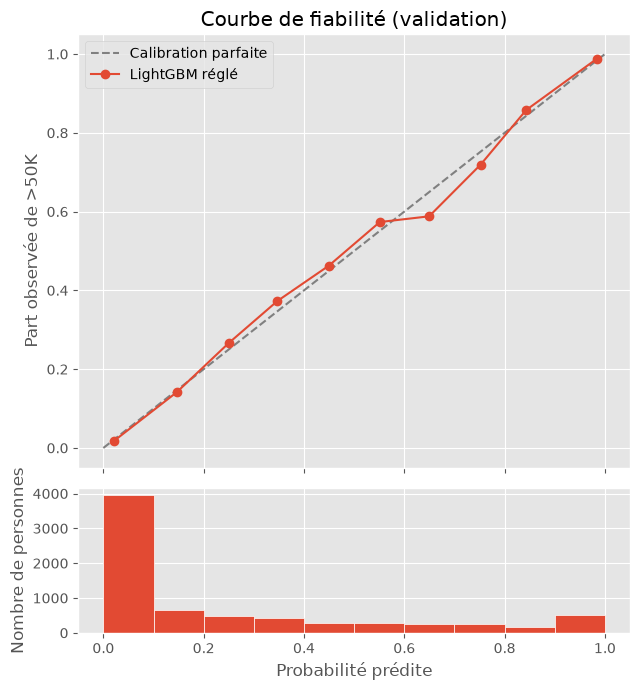

In [77]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

part_observee, probabilite_moyenne = calibration_curve(y_val, proba_final, n_bins=10)
ax1.plot([0, 1], [0, 1], "--", color="grey", label="Calibration parfaite")
ax1.plot(probabilite_moyenne, part_observee, "o-", label="LightGBM réglé")
ax1.set(ylabel="Part observée de >50K", title="Courbe de fiabilité (validation)")
ax1.legend()

# Histogramme : où le modèle place-t-il ses probabilités ?
ax2.hist(proba_final, bins=10, range=(0, 1), edgecolor="white")
ax2.set(xlabel="Probabilité prédite", ylabel="Nombre de personnes")

plt.tight_layout()
plt.show()

**Le modèle est bien calibré.** L'ECE vaut 0,010 : en moyenne, la probabilité prédite et la part réelle de `>50K` ne diffèrent que d'un point. Le score de Brier (0,086) est deux fois plus faible que celui d'une prédiction constante (0,182). La courbe de fiabilité suit la diagonale de près.

**Sur-confiant ou sous-confiant ?** Ni l'un ni l'autre de façon systématique, mais deux petites déviations :
- entre 0,2 et 0,6, le modèle est **légèrement sous-confiant** : la part observée dépasse la probabilité prédite de 1 à 3 points (par exemple 37,3 % observés pour 34,7 % prédits) ;
- entre 0,6 et 0,8, il est **légèrement sur-confiant** : 58,8 % observés pour 64,9 % prédits.

Ces tranches comptent chacune moins de 500 personnes : avec environ 270 personnes, la marge d'erreur sur une part observée est d'environ ±6 points. Les écarts sont donc du même ordre que le bruit d'échantillonnage.

L'histogramme montre que le modèle tranche souvent : plus de la moitié des personnes reçoivent une probabilité inférieure à 0,1, et 514 une probabilité supérieure à 0,9. Ces deux tranches extrêmes, les plus peuplées, sont aussi les mieux calibrées.

Ce bon résultat est cohérent avec deux choix précédents : LightGBM optimise la *log-loss*, qui récompense les probabilités justes, et nous n'avons utilisé ni pondération ni SMOTE (exigence 3), qui gonflent les probabilités.

#### 9.3 Faut-il recalibrer ?

On teste les deux méthodes de recalibration du cours. Le calibrateur doit être appris sur des prédictions faites sur des données que le modèle n'a pas vues : on utilise des prédictions **hors pli** sur le train (validation croisée à 5 plis), ce qui garde la validation pour l'évaluation et le test intact.
- **Platt** : une régression logistique sur le score du modèle (2 paramètres, forme en S) ;
- **isotonique** : une fonction croissante en escalier, plus flexible mais plus gourmande en données.

In [78]:
from sklearn.model_selection import cross_val_predict
from sklearn.isotonic import IsotonicRegression

# Prédictions « hors pli » sur le train : chaque personne est prédite par un modèle qui ne l'a pas vue
proba_hors_pli = cross_val_predict(construire_modele(clone(lgbm)), X_train, y_train,
                                   cv=validation_croisee, method="predict_proba")[:, 1]

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

platt = LogisticRegression().fit(logit(proba_hors_pli).reshape(-1, 1), y_train)
isotonique = IsotonicRegression(out_of_bounds="clip").fit(proba_hors_pli, y_train)

versions = {
    "Sans recalibration": proba_final,
    "Platt": platt.predict_proba(logit(proba_final).reshape(-1, 1))[:, 1],
    "Isotonique": isotonique.predict(proba_final),
}
pd.DataFrame({
    "score de Brier": [brier_score_loss(y_val, p) for p in versions.values()],
    "ECE": [ece(y_val, p) for p in versions.values()],
    "PR-AUC": [average_precision_score(y_val, p) for p in versions.values()],
}, index=list(versions)).round(4)

,score de Brier,ECE,PR-AUC
Sans recalibration,0.0862,0.0103,0.8346
Platt,0.0862,0.0103,0.8346
Isotonique,0.0863,0.0094,0.8243


**Aucune recalibration n'est utile.** Platt donne exactement les mêmes scores que le modèle brut : la correction apprise est quasiment l'identité, preuve que les probabilités étaient déjà justes. L'isotonique réduit très légèrement l'ECE (0,0094 contre 0,0103), mais dégrade le score de Brier et la PR-AUC (0,824 contre 0,835) : sa fonction en escalier regroupe des clients que le modèle distinguait. **On garde donc le modèle sans recalibration.**

#### 9.4 Calibration par sexe

Un modèle bien calibré en moyenne peut être mal calibré pour un groupe (séance 7). On vérifie donc la calibration séparément pour les femmes et les hommes.

In [79]:
pd.DataFrame([
    {"groupe": groupe,
     "probabilité moyenne prédite": proba_final[(X_val["sex"] == groupe).to_numpy()].mean(),
     "part observée de >50K": y_val[X_val["sex"] == groupe].mean(),
     "ECE": ece(y_val[X_val["sex"] == groupe], proba_final[(X_val["sex"] == groupe).to_numpy()])}
    for groupe in ["Female", "Male"]
]).set_index("groupe").round(3)

,probabilité moyenne prédite,part observée de >50K,ECE
groupe,,,
Female,0.111,0.102,0.016
Male,0.304,0.306,0.016


La calibration reste bonne dans les deux groupes (ECE de 0,016). Pour les femmes, le modèle surestime légèrement la part de `>50K` (11,1 % prédits pour 10,2 % observés) ; pour les hommes, il est quasiment exact (30,4 % contre 30,6 %).

**Ferions-nous confiance aux probabilités telles quelles ?** **Oui**, pour une décision en aval sur cette population : estimer le nombre de ventes attendues d'une campagne, ou classer les clients par probabilité. Une probabilité de 0,7 correspond bien à environ 70 % de `>50K`, à quelques points près dans les tranches intermédiaires. Trois réserves :
- la calibration est mesurée sur des données de 1994 : si la population de clients ou les revenus changent (inflation, autre clientèle), elle devra être revérifiée ;
- dans les tranches intermédiaires (0,2 à 0,8), l'écart peut atteindre quelques points, il faut donc éviter une précision excessive ;
- la confirmation finale se fera sur le test, lors de l'évaluation finale.

## <span style="color: red;">10 - Audit d'équité et de biais</span>

Le cadrage a fixé l'attribut sensible (`sex`) et la définition d'équité prioritaire : **l'égalité des chances**, c'est-à-dire le même rappel pour les femmes et les hommes. Une femme qui gagne plus de 50 K$ doit avoir autant de chances qu'un homme de recevoir l'offre. On calcule aussi les métriques des autres définitions, pour montrer ce qu'elles donnent :

| Définition | Métrique égalisée entre les groupes |
|---|---|
| Parité démographique | Part de personnes contactées |
| **Égalité des chances** (notre choix) | **Rappel** (taux de vrais positifs) |
| Égalité des erreurs (*equalized odds*) | Rappel **et** taux de faux positifs |
| Parité prédictive | Précision |

#### 10.1 Audit sur la validation

In [80]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate

METRIQUES_EQUITE = {
    "part contactée": selection_rate,              # parité démographique
    "rappel": true_positive_rate,                  # égalité des chances (notre définition)
    "taux de faux positifs": false_positive_rate,  # avec le rappel : égalité des erreurs
    "précision": lambda y, p: precision_score(y, p, zero_division=0),  # parité prédictive
}

def audit_equite(y_vrai, prediction, sexe):
    """Métriques d'équité par sexe, et écart entre les deux groupes."""
    cadre = MetricFrame(metrics=METRIQUES_EQUITE, y_true=y_vrai, y_pred=prediction, sensitive_features=sexe)
    tableau = cadre.by_group.copy()
    tableau.loc["écart (H - F)"] = tableau.loc["Male"] - tableau.loc["Female"]
    return tableau.round(3)

display(pd.DataFrame({
    "effectif": X_val.groupby("sex", observed=True).size(),
    "dont >50K": y_val.groupby(X_val["sex"], observed=True).sum(),
}))
audit_equite(y_val, (proba_final >= SEUIL_FINAL).astype(int), X_val["sex"])

,effectif,dont >50K
sex,,
Female,2402,246
Male,4917,1506


,part contactée,rappel,taux de faux positifs,précision
sex,,,,
Female,0.113,0.772,0.038,0.701
Male,0.361,0.805,0.164,0.684
écart (H - F),0.248,0.032,0.127,-0.018


**Lecture de l'audit (validation, seuil unique) :**
- **Égalité des chances (notre définition)** : rappel de 77,2 % pour les femmes contre 80,5 % pour les hommes, soit un écart de 3,2 points. Elle est presque respectée sur la validation.
- **Parité démographique** : fortement violée (11,3 % des femmes contactées contre 36,1 % des hommes), mais c'est attendu : seules 10,2 % des femmes sont `>50K`, contre 30,6 % des hommes. L'imposer obligerait à contacter des femmes `<=50K` ou à écarter des hommes `>50K`. C'est pourquoi nous ne l'avons pas retenue. Le ratio de parité (0,113 / 0,361 = 0,31) échouerait aussi la règle des quatre cinquièmes (seuil de 0,8).
- **Égalité des erreurs** : violée, car les hommes sont bien plus souvent contactés à tort (taux de faux positifs de 16,4 % contre 3,8 %).
- **Parité prédictive** : presque respectée (précision de 70,1 % contre 68,4 %).

Comme les taux de base diffèrent fortement (10,2 % contre 30,6 %), ces définitions ne peuvent pas être satisfaites toutes à la fois (théorème vu en cours). Le modèle n'utilise pas `sex`, mais `relationship` (`Husband` / `Wife`) en est un proxy, et les écarts de revenus de 1994 sont un **biais historique** que le modèle apprend.

#### 10.2 Mitigation : un seuil par sexe

On applique un **post-traitement** : un seuil de décision différent pour chaque sexe, choisi sur la validation pour que chaque groupe atteigne 80 % de rappel. Le modèle n'est pas réentraîné. À titre de comparaison, on applique aussi le `ThresholdOptimizer` de Fairlearn, avec la contrainte d'égalité des rappels.

In [81]:
from fairlearn.postprocessing import ThresholdOptimizer

# Un seuil par sexe, choisi sur la validation pour atteindre 80 % de rappel dans chaque groupe
seuils_par_sexe = {
    sexe: seuil_pour_rappel(y_val[X_val["sex"] == sexe], proba_final[(X_val["sex"] == sexe).to_numpy()])
    for sexe in ["Female", "Male"]
}
print("Seuils par sexe :", {sexe: round(seuil, 3) for sexe, seuil in seuils_par_sexe.items()},
      f"(seuil unique : {SEUIL_FINAL:.3f})")

# Comparaison : ThresholdOptimizer de Fairlearn, contrainte d'égalité des rappels, appris sur la validation
optimiseur = ThresholdOptimizer(estimator=modele_final, constraints="true_positive_rate_parity",
                                objective="balanced_accuracy_score", prefit=True, predict_method="predict_proba")
optimiseur.fit(X_val, y_val, sensitive_features=X_val["sex"])

Seuils par sexe : {'Female': np.float64(0.29), 'Male': np.float64(0.34)} (seuil unique : 0.339)


,estimator,Pipeline(step...verbose=-1))])
,constraints,'true_positive_rate_parity'
,objective,'balanced_accuracy_score'
,prefit,True
,predict_method,'predict_proba'
,grid_size,1000
,flip,False
,tol,None
Name,Type,Value
estimator_,Pipeline,Pipeline(step...verbose=-1))])
interpolated_thresholder_,InterpolatedThresholder,"InterpolatedT..., prefit=True)"


#### 10.3 Avant / après sur le test

Le test n'a servi à aucune décision jusqu'ici. On compare les trois versions sur ce jeu intact.

In [82]:
proba_test = modele_final.predict_proba(X_test)[:, 1]
predictions_test = {
    "Avant (seuil unique)": (proba_test >= SEUIL_FINAL).astype(int),
    "Après : seuil par sexe": (proba_test >= X_test["sex"].map(seuils_par_sexe).to_numpy(dtype=float)).astype(int),
    "Après : ThresholdOptimizer": optimiseur.predict(X_test, sensitive_features=X_test["sex"],
                                                     random_state=RANDOM_STATE),
}

lignes = []
for nom, prediction in predictions_test.items():
    audit = audit_equite(y_test, prediction, X_test["sex"])
    lignes.append({
        "version": nom,
        "précision": precision_score(y_test, prediction),
        "rappel": recall_score(y_test, prediction),
        "F1": f1_score(y_test, prediction),
        "rappel femmes": audit.loc["Female", "rappel"],
        "rappel hommes": audit.loc["Male", "rappel"],
        "écart de rappel": audit.loc["écart (H - F)", "rappel"],
    })
pd.DataFrame(lignes).set_index("version").round(3)

,précision,rappel,F1,rappel femmes,rappel hommes,écart de rappel
version,,,,,,
Avant (seuil unique),0.656,0.794,0.718,0.699,0.810,0.111
Après : seuil par sexe,0.652,0.800,0.718,0.738,0.810,0.072
Après : ThresholdOptimizer,0.607,0.858,0.711,0.785,0.871,0.086


In [83]:
# Détail complet des métriques d'équité, avant et après le seuil par sexe
for nom in ["Avant (seuil unique)", "Après : seuil par sexe"]:
    print(nom)
    display(audit_equite(y_test, predictions_test[nom], X_test["sex"]))

Avant (seuil unique)


,part contactée,rappel,taux de faux positifs,précision
sex,,,,
Female,0.121,0.699,0.052,0.613
Male,0.373,0.810,0.181,0.663
écart (H - F),0.251,0.111,0.128,0.050


Après : seuil par sexe


,part contactée,rappel,taux de faux positifs,précision
sex,,,,
Female,0.135,0.738,0.064,0.580
Male,0.372,0.810,0.179,0.665
écart (H - F),0.236,0.072,0.116,0.085


**Avant mitigation, l'écart de rappel est plus grand sur le test que sur la validation** : 11,1 points (69,9 % contre 81,0 %), contre 3,2 points. Le test ne compte que 256 femmes `>50K` : sur un tel effectif, le rappel a une marge d'erreur d'environ ±5,6 points. L'écart réel se situe donc probablement entre ces deux valeurs. Cette instabilité est en soi un constat : un audit d'équité sur un petit groupe doit être accompagné de son incertitude.

**Effet des deux mitigations (test) :**
- **Un seuil par sexe** réduit l'écart de rappel de 11,1 à 7,2 points, en gardant un rappel global de 80 %, pour un coût quasi nul : la précision passe de 0,656 à 0,652, et le F1 reste à 0,718. L'écart ne disparaît pas, car les seuils ont été choisis sur la validation, où l'écart était faible.
- **`ThresholdOptimizer`** réduit l'écart à 8,6 points, mais déplace le point de fonctionnement : le rappel global monte à 85,8 % et la précision chute à 0,607, car il optimise l'exactitude équilibrée et non notre contrainte de 80 % de rappel. Ses décisions sont de plus aléatoires pour certains clients.

**Décision : nous retenons le seuil par sexe**, qui réduit l'écart d'égalité des chances sans dégrader les performances.

**Limites et choix de politique :** cette mitigation utilise le sexe **au moment de la décision**, ce qui est en soi une question juridique et éthique : dans certains pays, traiter différemment selon le sexe est interdit, même pour corriger une inégalité. Elle ne corrige pas non plus la cause : le biais historique des données de 1994 et le proxy `relationship`. Une alternative serait de retirer `relationship` du modèle et de mesurer le compromis entre performance et équité.

## <span style="color: red;">11 - Évaluation finale sur le test</span>

Performance finale du modèle retenu (LightGBM réglé, seuil unique choisi sur la validation), mesurée une seule fois sur le test, comparée à la validation. Le résultat est aussi enregistré dans MLflow.

In [84]:
resultats_finaux = []
for jeu, y_jeu, proba_jeu in [("validation", y_val, proba_final), ("test", y_test, proba_test)]:
    resultat = evaluer(f"LightGBM réglé ({jeu})", y_jeu, proba_jeu, SEUIL_FINAL)
    resultat["Brier"] = brier_score_loss(y_jeu, proba_jeu)
    resultat["ECE"] = ece(y_jeu, proba_jeu)
    resultats_finaux.append(resultat)

with mlflow.start_run(run_name="Test - LightGBM final"):
    test = resultats_finaux[1]
    mlflow.log_metrics({"pr_auc_test": test["PR-AUC"], "roc_auc_test": test["ROC-AUC"],
                        "precision_test": test["précision"], "rappel_test": test["rappel"],
                        "f1_test": test["F1"], "brier_test": test["Brier"], "ece_test": test["ECE"]})

pd.DataFrame(resultats_finaux).set_index("modèle").round(3)

,seuil,PR-AUC,ROC-AUC,précision,rappel,F1,Brier,ECE
modèle,,,,,,,,
LightGBM réglé (validation),0.339,0.835,0.932,0.686,0.800,0.739,0.086,0.010
LightGBM réglé (test),0.339,0.824,0.927,0.656,0.794,0.718,0.089,0.009


**Sur le test, le modèle final obtient une PR-AUC de 0,824** (contre 0,239 au hasard), une ROC-AUC de 0,927, une précision de 65,6 % et un rappel de 79,4 %.

- La légère baisse par rapport à la validation (PR-AUC de 0,835 à 0,824) est attendue : la validation a servi à choisir le modèle et le seuil, ses scores sont donc un peu optimistes. Le score du test est l'estimation honnête de la performance sur de nouveaux clients.
- Le rappel est de 79,4 %, juste sous l'objectif de 80 % : le seuil, choisi sur la validation, ne transpose pas exactement. C'est l'illustration concrète qu'un seuil réglé sur un jeu de données n'est qu'une estimation pour un autre.
- **La calibration est confirmée** : ECE de 0,009 et Brier de 0,089, comme sur la validation.